# JSE Top 40: EDA, experimentation, optimisation and longitudinal review

Run the cells in order. The study contains **40 economic groups represented by 41 securities** at each of 2025-06-30, 2025-12-31 and 2026-06-30. INL and INP are the two Investec DLC securities. Membership is date-specific.

This notebook makes the experiment trail visible: all declared parameter combinations, invalid exclusions, both quality scores, selected parameters, all-date dendrograms, stable/shifted instruments, descriptive geometric screens, sector context and SHAP. It is a descriptive screening study, with unresolved historical source certification.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from paper_experiments import PaperExperiment
study = PaperExperiment(run_id=os.environ.get("JSE_PAPER_RUN_ID"))
print(study.out)

Paper experiment: paper-exhaustive-k8-01
C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\experiments\runs\paper-exhaustive-k8-01

C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\experiments\runs\paper-exhaustive-k8-01

## 1. EDA before modelling

Inspect population, source evidence, flagged missing cases, common-scale distributions and correlations. June 2025 preprocessing is frozen for later dates. The data are overlapping historical populations, not 123 independent firms.

,decision_date,instruments,distinct_tickers,fundamental_imputations,volume_imputations,economic_groups
0,2025-06-30,41,41,1,1,40
1,2025-12-31,41,41,1,1,40
2,2026-06-30,41,41,1,0,40


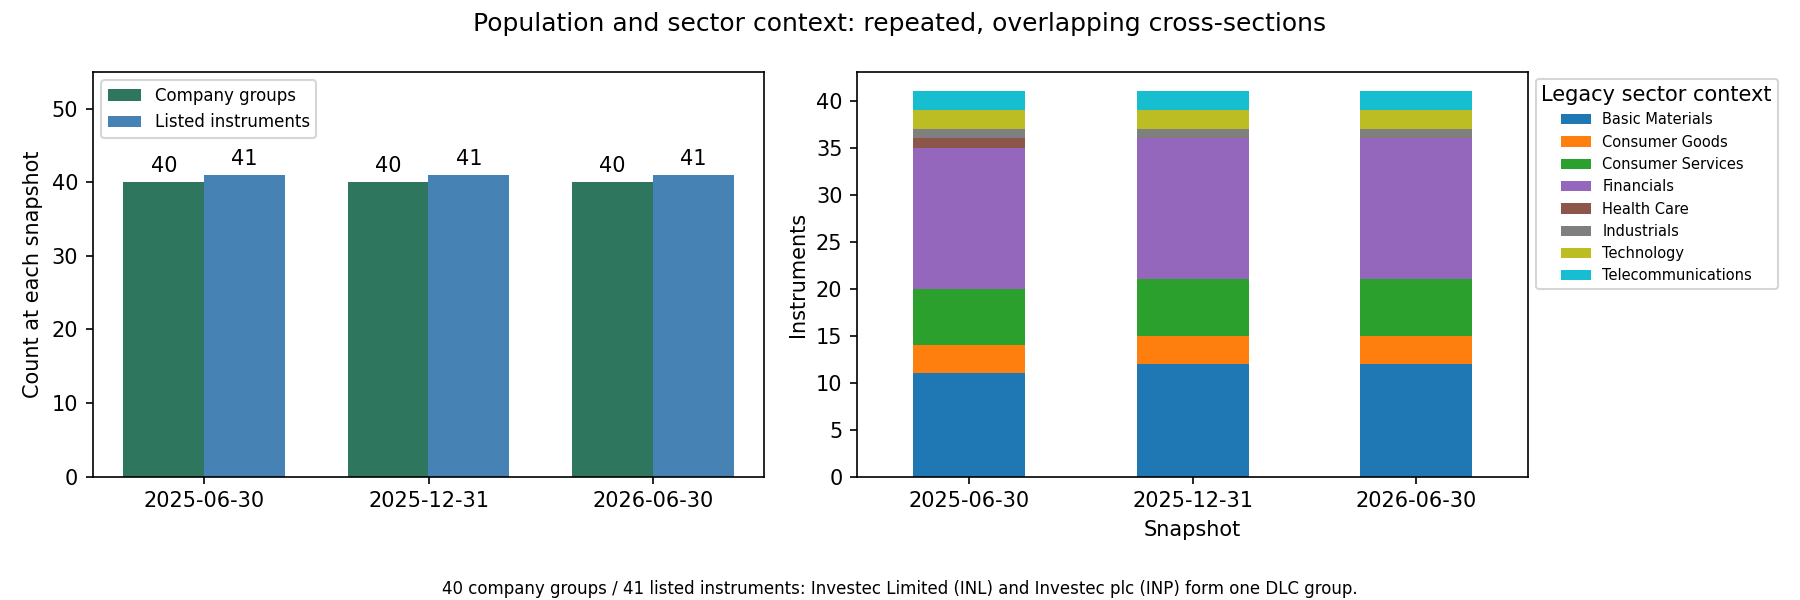

,decision_date,feature,raw_missing,model_missing
0,2025-06-30,return_1y,0,0
1,2025-06-30,average_daily_volume_1y_model,1,0
2,2025-06-30,market_cap_zar,0,0
3,2025-06-30,beta_1y,0,0
4,2025-06-30,shares_outstanding,0,0
5,2025-06-30,revenue_zar_model,1,0
6,2025-06-30,eps_zar_model,1,0
7,2025-06-30,annualised_volatility_1y,0,0
8,2025-06-30,dividend_yield,0,0
9,2025-06-30,earnings_yield_model_clipped,1,0


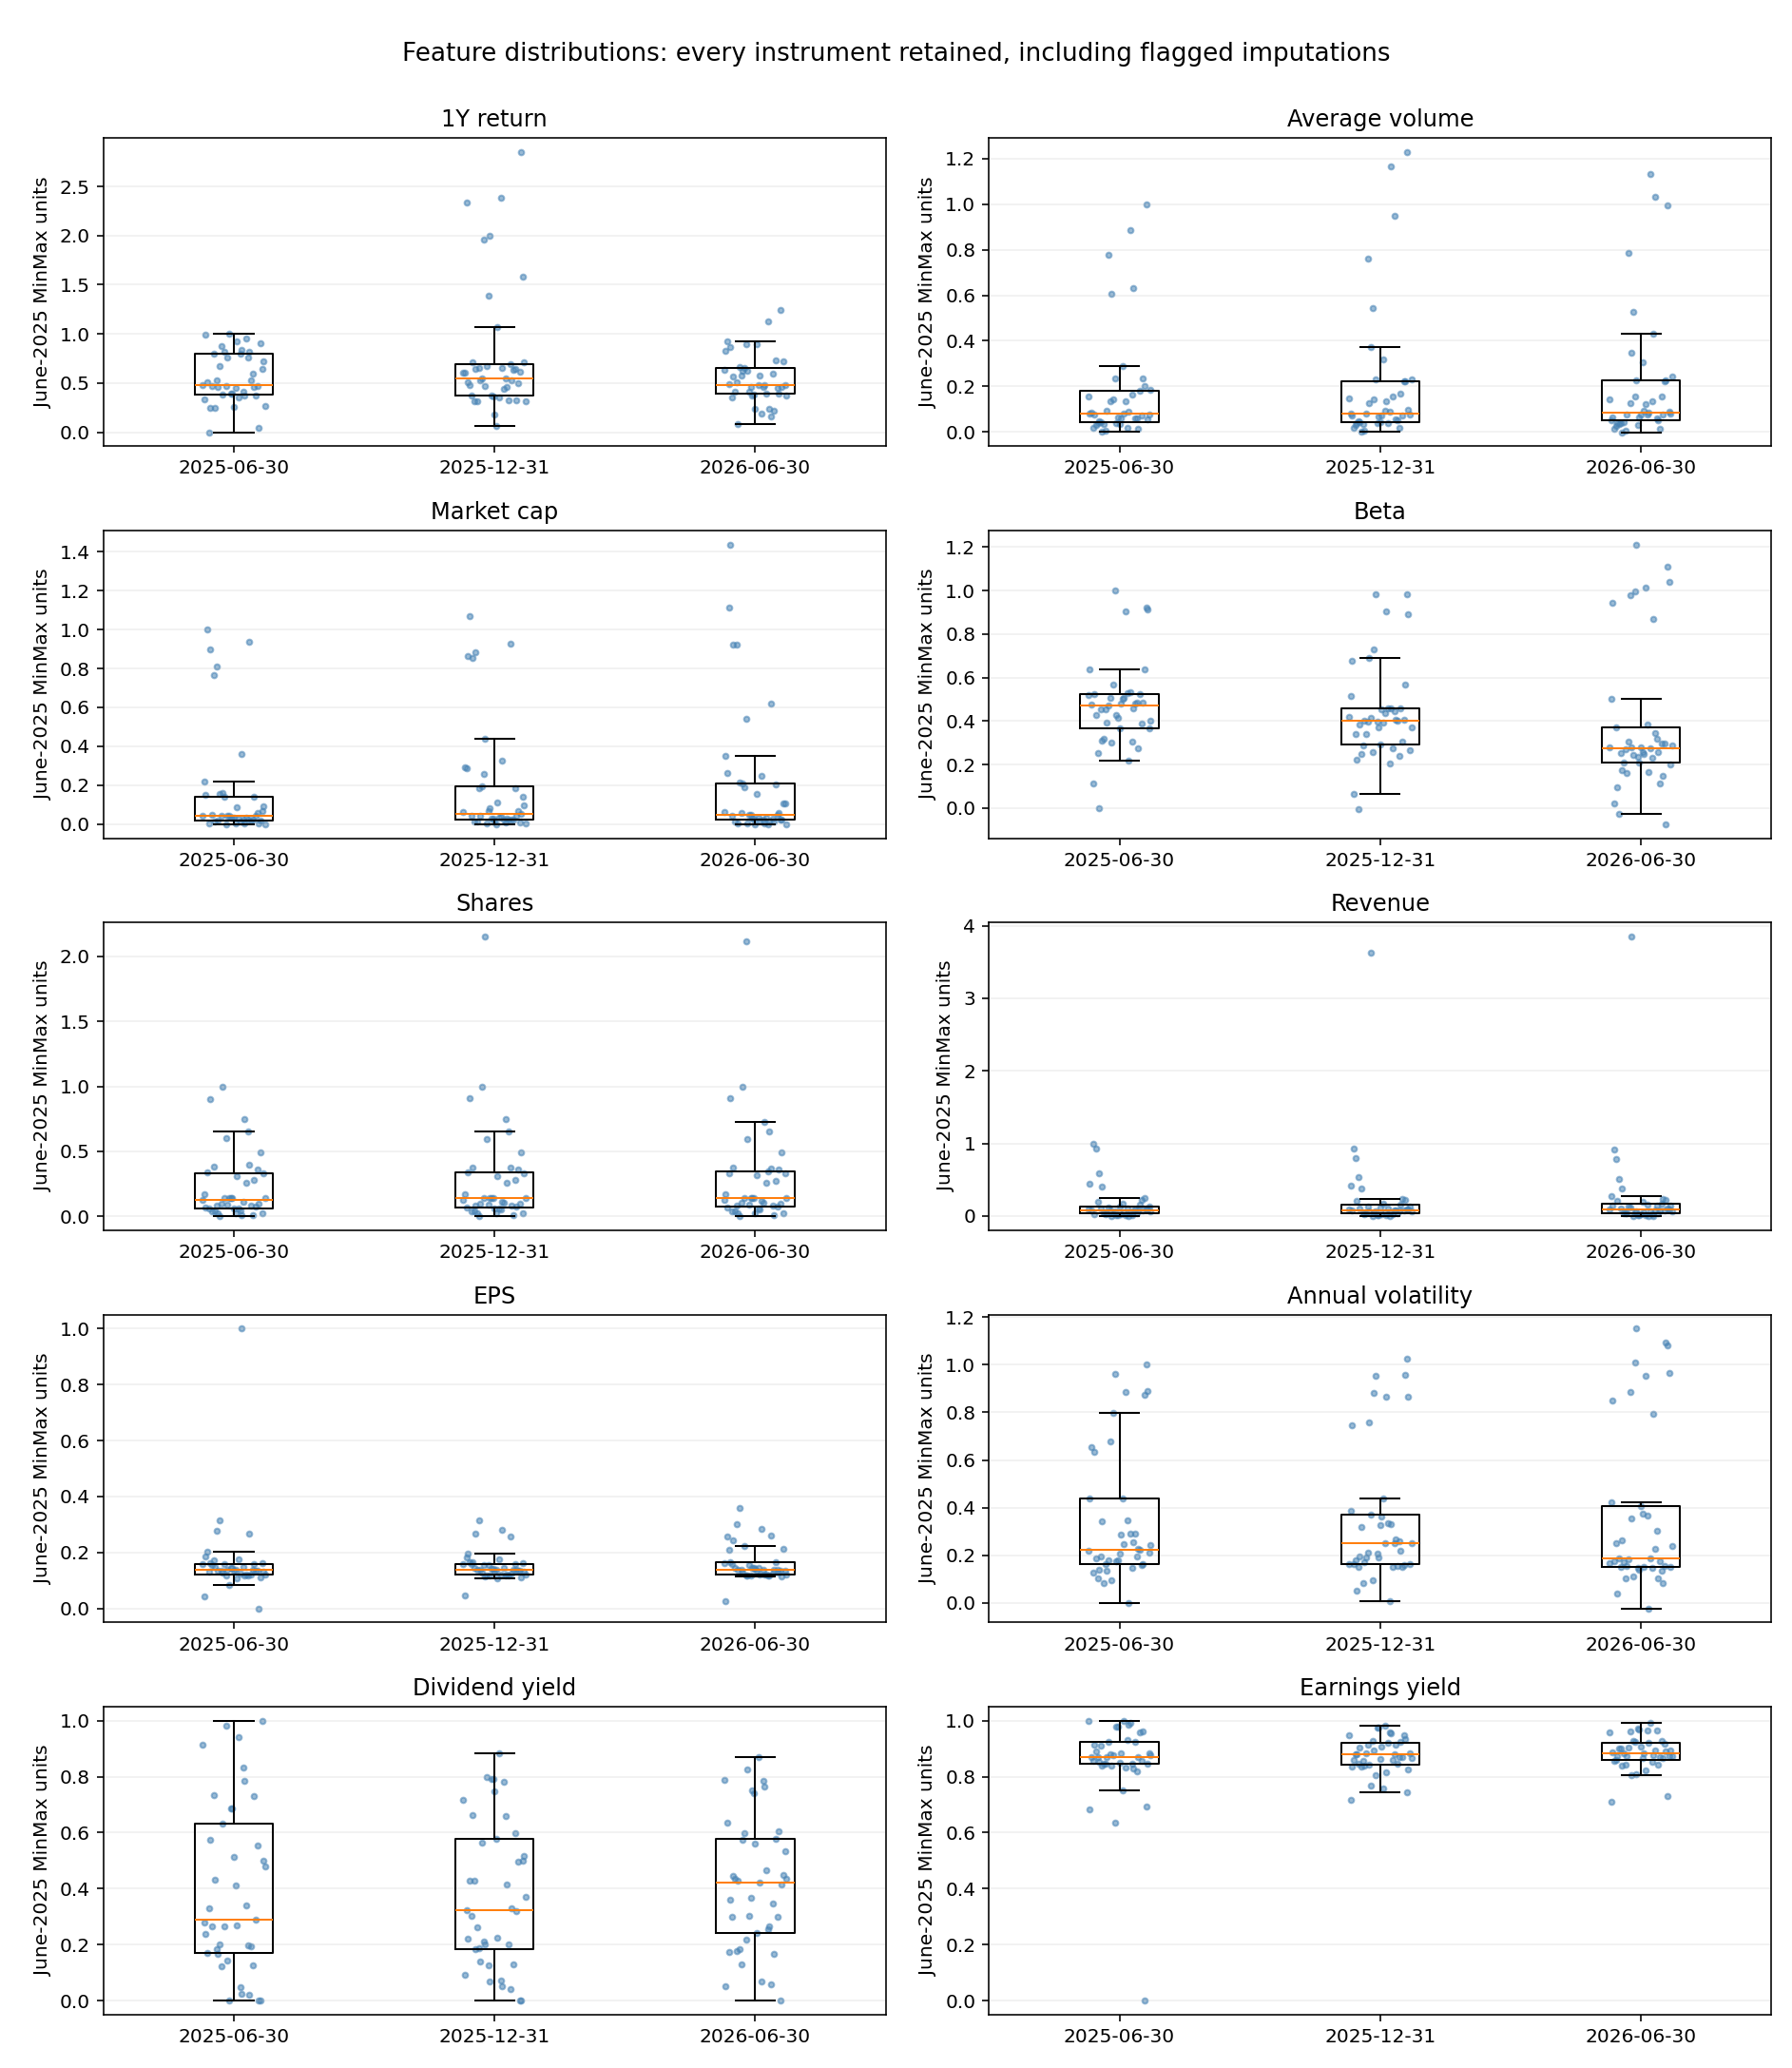

In [2]:
display(study.explore())
study.show_figure("eda/population_and_sectors.png")
display(study.table("eda/missingness.csv"))
study.show_figure("eda/feature_distributions.png")

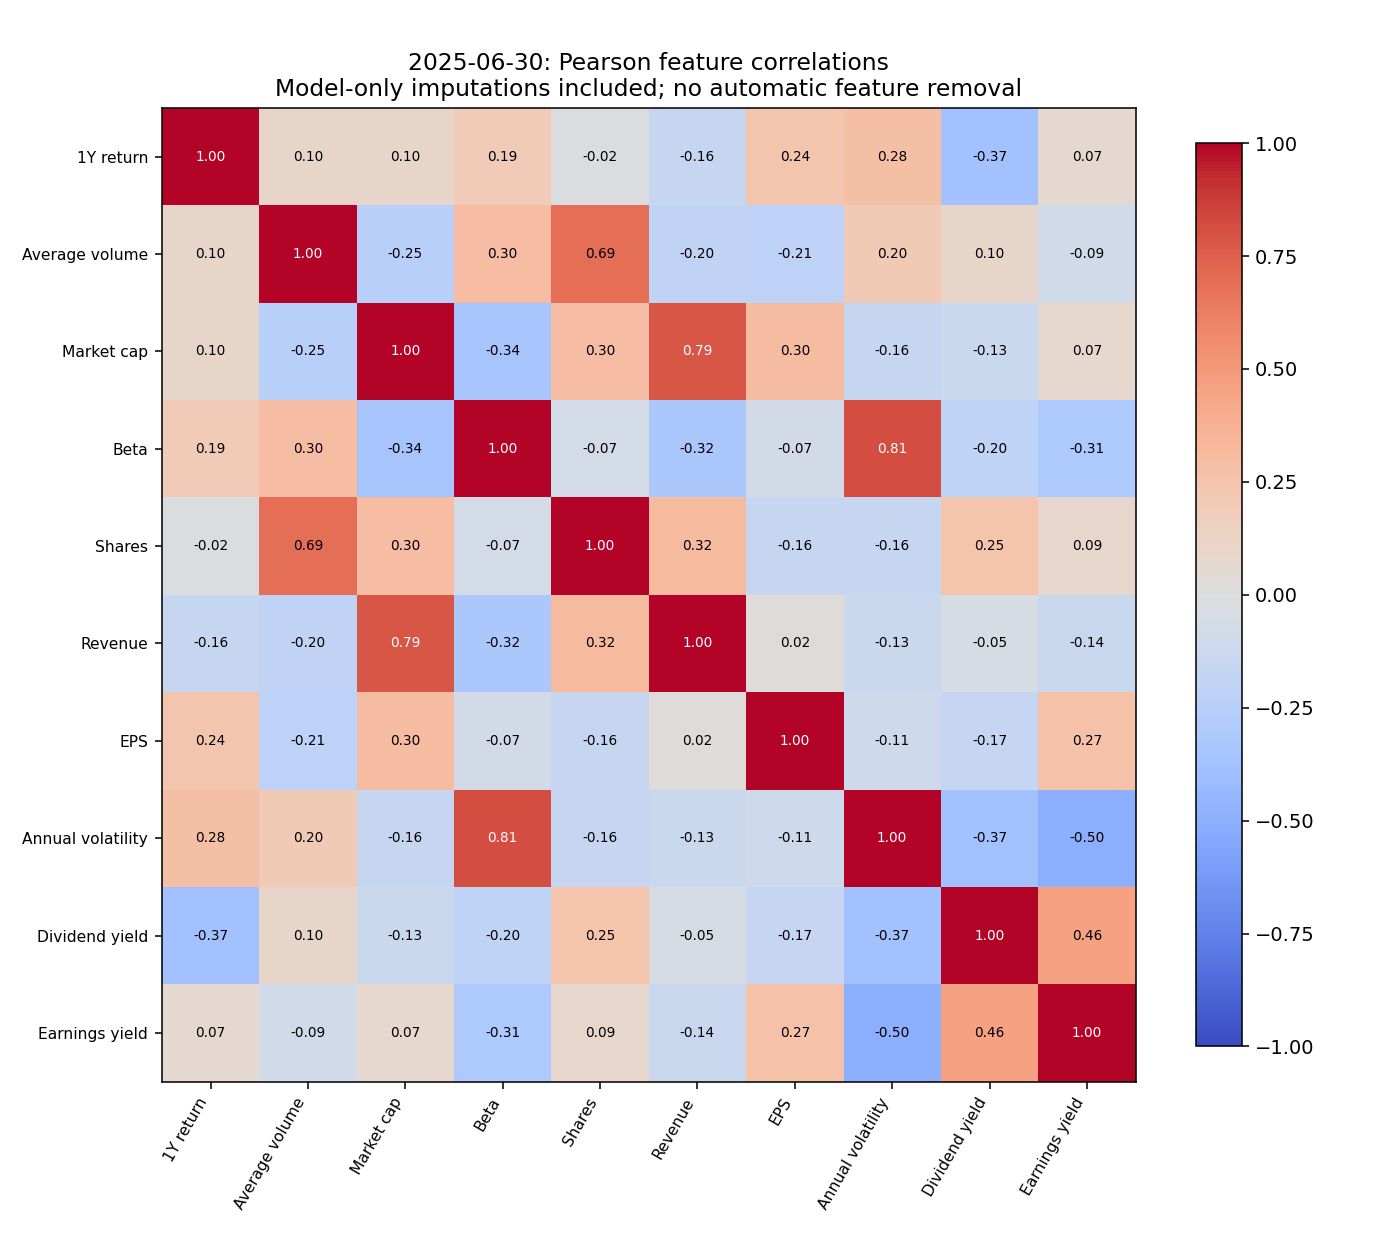

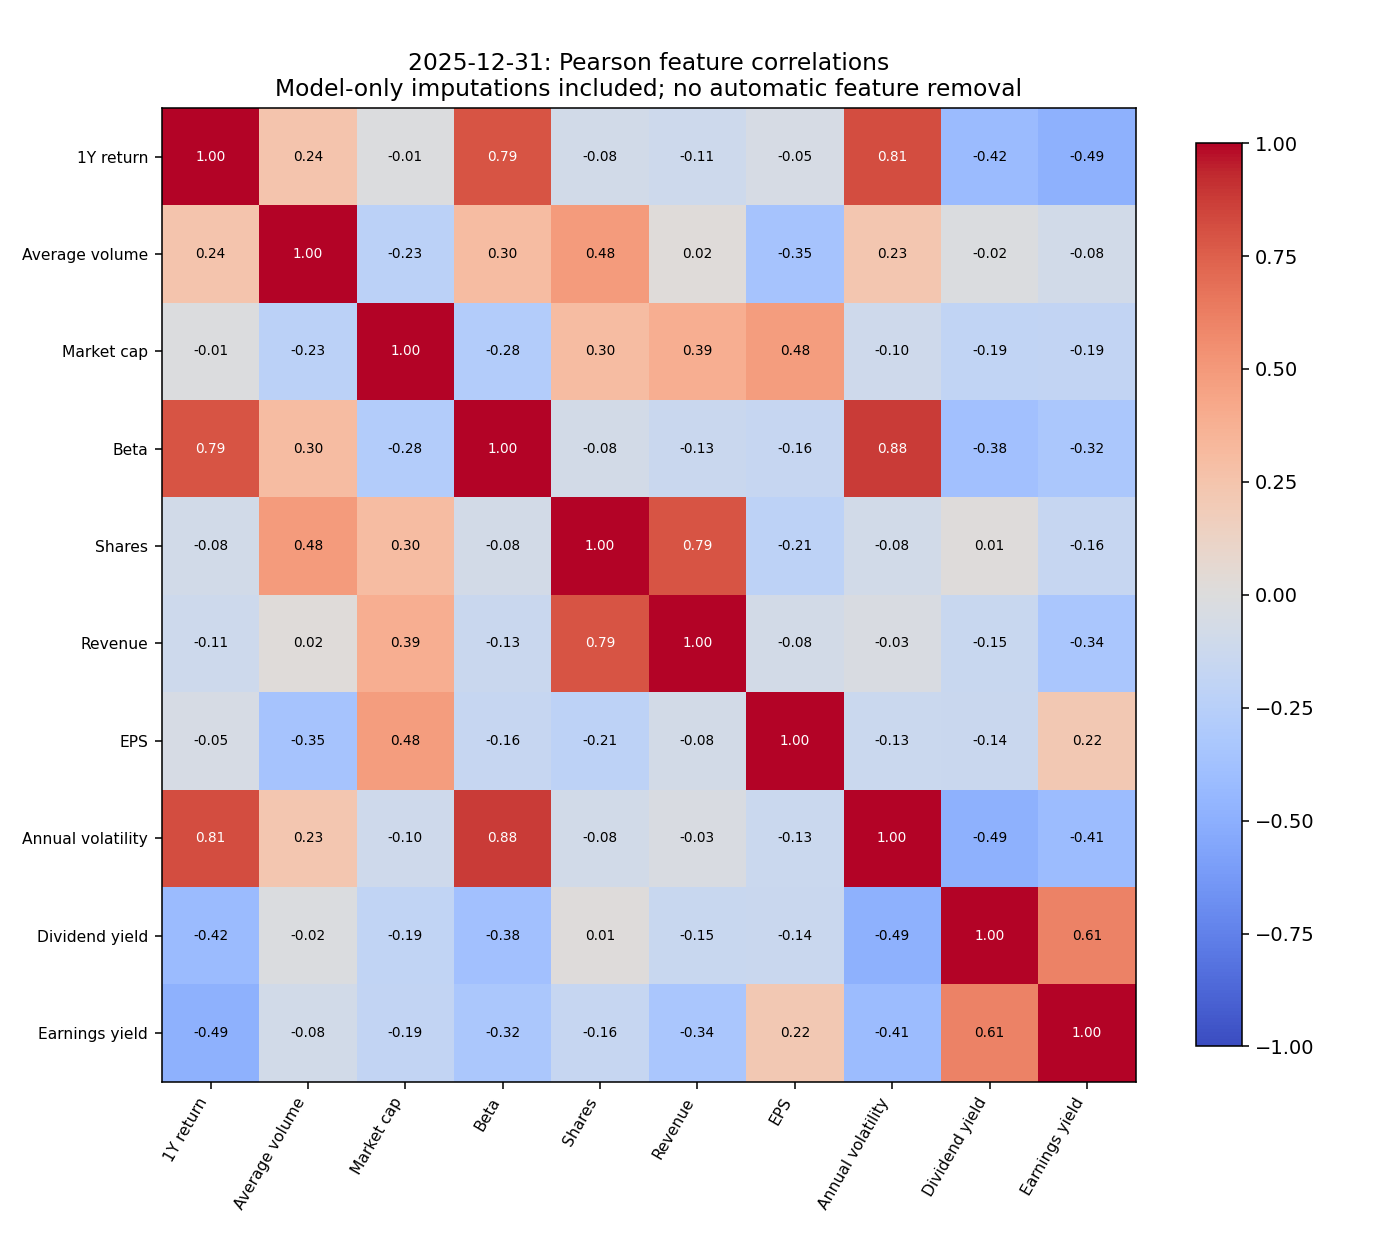

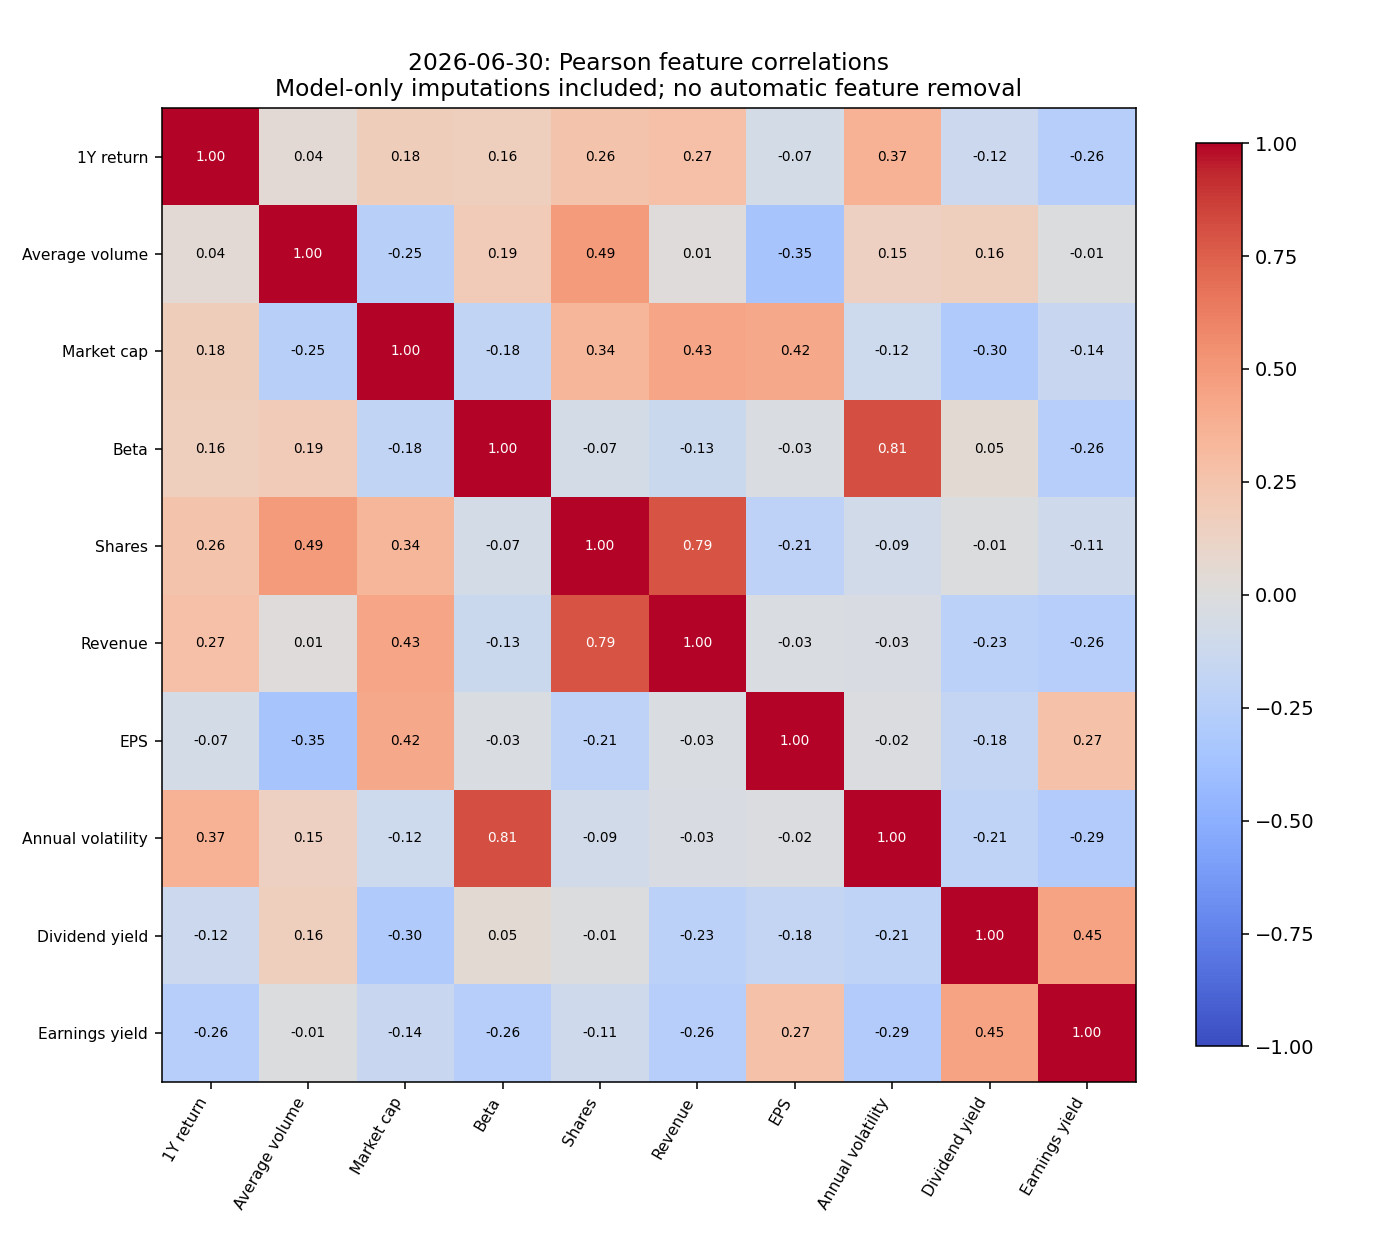

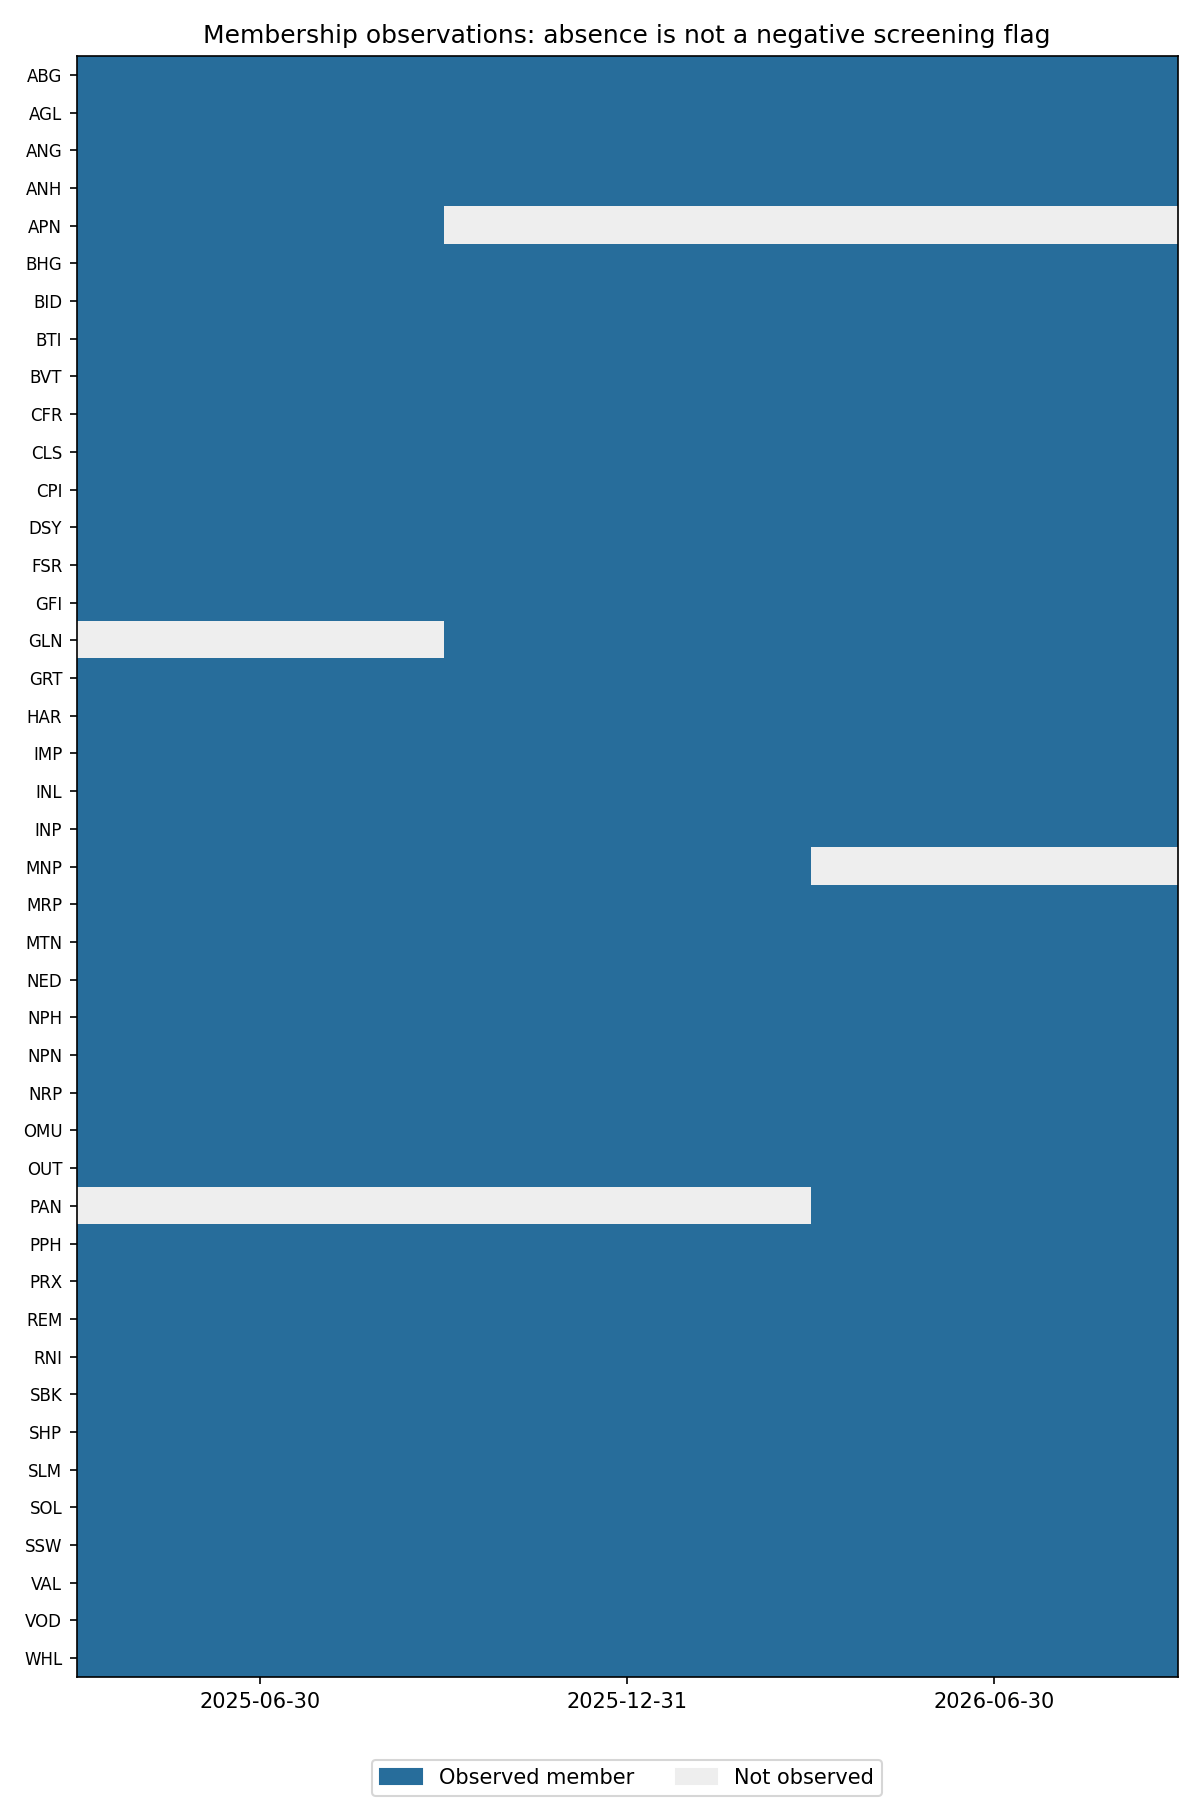

,decision_date,field,status,n
0,2025-06-30,membership_evidence,VERIFIED,41
1,2025-12-31,membership_evidence,VERIFIED,41
2,2026-06-30,membership_evidence,VERIFIED,41
3,2025-06-30,fundamentals_evidence,DATED_ISSUER_RELEASE,40
4,2025-06-30,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
5,2025-12-31,fundamentals_evidence,DATED_ISSUER_RELEASE,40
6,2025-12-31,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
7,2026-06-30,fundamentals_evidence,DATED_ISSUER_RELEASE,40
8,2026-06-30,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
9,2025-06-30,market_evidence,RETROSPECTIVE_VENDOR_DAILY_HISTORY,41


In [3]:
for date in study.config["dates"]:
    study.show_figure(f"eda/correlation_{date}.png")
study.show_figure("eda/membership_presence.png")
display(study.table("eda/evidence.csv"))

## 2. Declare and run all valid combinations in the finite grid

The exact grid is in `configs/paper_experiments.json`. **86 representations ? 38 clustering settings = 3,268 configurations; five seeds = 16,340 selection fits**. A representation is fitted once per seed and reused across clustering settings.

- PCA: two components or enough for 95% variance (potentially more than two).
- t-SNE: perplexities 5/10/20; learning rates 10/auto; 300/1000 iterations; Euclidean/Manhattan/cosine input distances.
- UMAP: neighbours 3/5/10/20; min_dist 0/0.01/0.1/0.5; Euclidean/Manhattan/cosine input distances.
- Hierarchical: single/complete/average with Euclidean/Manhattan/Chebyshev/cosine; Ward with Euclidean only. k=8.
- K-Means: k=8, n_init=20, Euclidean squared-distance objective.
- DBSCAN: eps 0.3/0.5/0.8/1.2; min_samples 3/5; Euclidean/Manhattan/cosine after axis standardization. Actual cluster/noise counts remain explicit.

Ward plus non-Euclidean distances is invalid and excluded explicitly. k is fixed at 8 for the paper's hierarchical/K-Means comparisons. Other k values are later diagnostics. This is exhaustive **within the declared finite grid**, not every possible parameter value or a guaranteed global optimum.

In [4]:
display(Markdown("```json\n" + json.dumps(study.config, indent=2) + "\n```"))
study.experiment()
display(study.table("search/candidate_summary.csv").head(10))

```json
{
  "experiment": "paper-eda-exhaustive-grid-and-longitudinal-v1",
  "selection_date": "2025-06-30",
  "dates": [
    "2025-06-30",
    "2025-12-31",
    "2026-06-30"
  ],
  "seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "pca_components": [
    2,
    0.95
  ],
  "tsne_perplexities": [
    5,
    10,
    20
  ],
  "tsne_learning_rates": [
    10,
    "auto"
  ],
  "tsne_iterations": [
    300,
    1000
  ],
  "reduction_metrics": [
    "euclidean",
    "manhattan",
    "cosine"
  ],
  "umap_neighbors": [
    3,
    5,
    10,
    20
  ],
  "umap_min_dist": [
    0.0,
    0.01,
    0.1,
    0.5
  ],
  "linkages": [
    "single",
    "complete",
    "average",
    "ward"
  ],
  "clustering_metrics": [
    "euclidean",
    "manhattan",
    "chebyshev",
    "cosine"
  ],
  "k": 8,
  "k_diagnostics": [
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12
  ],
  "kmeans_n_init": 20,
  "dbscan_eps": [
    0.3,
    0.5,
    0.8,
    1.2
  ],
  "dbscan_min_samples": [
    3,
    5
  ],
  "dbscan_metrics": [
    "euclidean",
    "manhattan",
    "cosine"
  ],
  "maximum_representations": 86,
  "maximum_configurations": 3268,
  "maximum_selection_fits": 16340,
  "primary_selection": "common_features_k8",
  "selection_rule": "Full coverage and valid scores on every seed; exactly 8 clusters. Minimize mean-silhouette descending rank plus mean-DB ascending rank in common June-scaled features. Tie-break by pairwise seed ARI, feature silhouette, candidate ID. Embedding-space ranking is an explicit alternative. Sector labels never select models.",
  "hotelling": {
    "dimensions": 2,
    "alpha": 0.05,
    "statistic": "individual squared Mahalanobis distance from same-snapshot mean, unbiased sample covariance, no n multiplier",
    "f_reference": "p*(n-1)/(n-p) * F.ppf(1-alpha,p,n-p); descriptive paper-style reference, not an individual-distance null calibration",
    "singular_covariance": "no threshold flag; report not estimable",
    "seed_support_fraction": 0.6,
    "confirmed_outliers": "None confirmed solely by screens, seed agreement, singleton status or SHAP; external substantive validation required"
  },
  "temporal_alignment": "Hungarian maximum Jaccard on common members, sorted labels, deterministic solver; reject zero-overlap matches; fresh IDs never reused; compare overlap objective and direct baseline alignment",
  "promotion": false,
  "scope": "Exhaustive within this finite grid, not all possible real-valued parameters or a global optimum. Later dates already examined: descriptive follow-ups, not untouched validation."
}
```

,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,davies_bouldin_features_max,seed_ari_mean,seed_ari_min,seed_nmi_mean,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters
0,c_0000034ded17ec81,5,5,1.000000,3,4,0,0.782289,0.046259,0.710976,...,1.569117,0.972863,0.932157,0.967472,True,umap,r_cd176439ce6340b8,dbscan,"{""metric"": ""cosine"", ""min_dist"": 0.0, ""n_compo...","{""eps"": 0.8, ""metric"": ""euclidean"", ""min_sampl..."
1,c_00180581760c35c4,5,5,1.000000,8,8,0,0.427832,0.031959,0.398475,...,1.560147,0.610810,0.491641,0.790017,True,umap,r_7cb119f6d1b4eb8f,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.1, ""n_compo...","{""linkage"": ""complete"", ""metric"": ""manhattan"",..."
2,c_00239b76799db031,5,5,0.829268,3,6,0,0.761885,0.089269,0.628441,...,1.469912,0.662244,0.385919,0.836136,False,umap,r_cd176439ce6340b8,dbscan,"{""metric"": ""cosine"", ""min_dist"": 0.0, ""n_compo...","{""eps"": 0.3, ""metric"": ""euclidean"", ""min_sampl..."
3,c_00302588c28af7ce,5,5,1.000000,8,8,0,0.402024,0.046540,0.356003,...,1.344755,0.613812,0.460854,0.788759,True,umap,r_7cb119f6d1b4eb8f,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.1, ""n_compo...","{""linkage"": ""complete"", ""metric"": ""chebyshev"",..."
4,c_0035d457dc420691,5,5,1.000000,8,8,2,0.407966,0.026673,0.381029,...,1.247267,0.795993,0.684270,0.869041,True,tsne,r_bed70ca2a60338a3,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""average"", ""metric"": ""chebyshev"", ..."
5,c_0042e9ac954711c8,5,2,0.121951,1,2,0,0.657330,0.124075,0.569596,...,0.914563,NaN,NaN,NaN,False,tsne,r_9839edd282b93854,dbscan,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""eps"": 0.5, ""metric"": ""manhattan"", ""min_sampl..."
6,c_0049009f4d45699d,5,5,1.000000,8,8,2,0.406153,0.060267,0.349435,...,1.341957,0.675957,0.539998,0.836573,True,umap,r_2573c35a43a455f7,hierarchical,"{""metric"": ""manhattan"", ""min_dist"": 0.1, ""n_co...","{""linkage"": ""single"", ""metric"": ""euclidean"", ""..."
7,c_004956491f0f0d62,5,0,1.000000,1,1,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,umap,r_b2f9229960f2e255,dbscan,"{""metric"": ""cosine"", ""min_dist"": 0.5, ""n_compo...","{""eps"": 1.2, ""metric"": ""euclidean"", ""min_sampl..."
8,c_005221a4c66ab1c3,5,0,1.000000,1,1,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,umap,r_84d4a5dda9f2b3dd,dbscan,"{""metric"": ""euclidean"", ""min_dist"": 0.0, ""n_co...","{""eps"": 0.5, ""metric"": ""cosine"", ""min_samples""..."
9,c_00529c043a4eeb37,5,5,0.682927,6,7,0,0.581345,0.044916,0.536928,...,1.128474,0.952975,0.857745,0.982532,False,tsne,r_c4a96272846273ed,dbscan,"{""init"": ""random"", ""learning_rate"": ""auto"", ""m...","{""eps"": 0.3, ""metric"": ""euclidean"", ""min_sampl..."


## 3. Select with BOTH silhouette and Davies?Bouldin

On June 2025, require valid scores and full coverage on every seed, and eight clusters for the overall paper comparison. Minimise the sum of ranks: mean silhouette descending and mean DB ascending. Tie-break by seed ARI, feature silhouette and deterministic candidate ID.

The **primary criterion uses common June-scaled financial features** to compare the same geometry across reductions. A separate embedding criterion shows how the apparent winner changes with the score space. Sector ARI/NMI never tune the model. DB uses Euclidean centroids; score geometry differs from some fitting distances. Inspect individual metric champions and Pareto sets, not only the joint winner. A family without an eligible candidate is reported rather than silently removed.

Settings are frozen from June 2025 and reused at later dates. Because later dates have already been examined in this project, they are descriptive follow-ups, not untouched validation sets.

,role,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,...,davies_bouldin_features_max,seed_ari_mean,seed_ari_min,seed_nmi_mean,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters
0,common_features_k8,c_073540362ecaaa17,5,5,1.0,8,8,4,0.256960,0.000000,...,0.683958,1.000000,1.000000,1.000000,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""euclidean"", ..."
1,features_pca_hierarchical,c_270de6df6144c04c,5,5,1.0,8,8,3,0.299198,0.000000,...,0.720015,1.000000,1.000000,1.000000,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""chebyshev"", ..."
2,features_pca_kmeans,c_7d1d69927f9f3bf0,5,5,1.0,8,8,2,0.264238,0.009053,...,0.946197,0.708693,0.545954,0.872893,True,pca,r_81b710484643a5c4,kmeans,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""n_clusters"": 8, ""n_init"": 20}"
3,features_tsne_dbscan,c_79448941048b352e,5,5,1.0,2,3,0,0.280753,0.088810,...,1.142436,0.477141,-0.082184,0.511111,True,tsne,r_cf99830e94994666,dbscan,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""eps"": 0.8, ""metric"": ""euclidean"", ""min_sampl..."
4,features_tsne_hierarchical,c_7362fc096868a7b4,5,5,1.0,8,8,3,0.172483,0.087193,...,0.905730,0.731383,0.525130,0.856563,True,tsne,r_cf99830e94994666,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""single"", ""metric"": ""chebyshev"", ""..."
5,features_tsne_kmeans,c_81df66beccbdd3bc,5,5,1.0,8,8,1,0.448696,0.010407,...,1.235175,0.720689,0.613834,0.852157,True,tsne,r_bed70ca2a60338a3,kmeans,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""n_clusters"": 8, ""n_init"": 20}"
6,features_umap_dbscan,c_ecdf1240e2435ac4,5,5,1.0,2,2,0,0.122171,0.050565,...,1.142436,0.343027,-0.094955,0.423286,True,umap,r_3cc0350cc1503268,dbscan,"{""metric"": ""cosine"", ""min_dist"": 0.0, ""n_compo...","{""eps"": 0.8, ""metric"": ""manhattan"", ""min_sampl..."
7,features_umap_hierarchical,c_c31a5a00879f0102,5,5,1.0,8,8,1,0.719104,0.083408,...,1.206543,0.877303,0.742318,0.945704,True,umap,r_82280a6eb317e0d1,hierarchical,"{""metric"": ""euclidean"", ""min_dist"": 0.0, ""n_co...","{""linkage"": ""single"", ""metric"": ""chebyshev"", ""..."
8,features_umap_kmeans,c_e42e8f91feb4c6b9,5,5,1.0,8,8,0,0.555741,0.032469,...,1.291106,0.771391,0.655959,0.878535,True,umap,r_08973367e2e8f338,kmeans,"{""metric"": ""euclidean"", ""min_dist"": 0.5, ""n_co...","{""n_clusters"": 8, ""n_init"": 20}"
9,embedding_k8,c_152cbd6e85993337,5,5,1.0,8,8,0,0.800419,0.030982,...,1.277982,1.000000,1.000000,1.000000,True,umap,r_deca05f82c54a9d1,kmeans,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""n_clusters"": 8, ""n_init"": 20}"


,geometry,representation,algorithm,candidate_id,status,silhouette_embedding_mean,davies_bouldin_embedding_mean,silhouette_features_mean,davies_bouldin_features_mean,seed_ari_mean,n_clusters_min,n_clusters_max
0,features,pca,dbscan,NaN,No valid full-coverage candidate on every seed...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,features,pca,hierarchical,c_270de6df6144c04c,full-coverage all-seed joint winner,0.299198,0.682701,0.292587,0.720015,1.000000,8.0,8.0
2,features,pca,kmeans,c_7d1d69927f9f3bf0,full-coverage all-seed joint winner,0.264238,0.845342,0.246128,0.895938,0.708693,8.0,8.0
3,features,tsne,dbscan,c_79448941048b352e,full-coverage all-seed joint winner,0.280753,0.664352,0.320088,1.009751,0.477141,2.0,3.0
4,features,tsne,hierarchical,c_7362fc096868a7b4,full-coverage all-seed joint winner,0.172483,0.693175,0.224072,0.802295,0.731383,8.0,8.0
5,features,tsne,kmeans,c_81df66beccbdd3bc,full-coverage all-seed joint winner,0.448696,0.649191,0.202799,1.076975,0.720689,8.0,8.0
6,features,umap,dbscan,c_ecdf1240e2435ac4,full-coverage all-seed joint winner,0.122171,1.154555,0.304128,1.140234,0.343027,2.0,2.0
7,features,umap,hierarchical,c_c31a5a00879f0102,full-coverage all-seed joint winner,0.719104,0.286169,0.170419,1.133765,0.877303,8.0,8.0
8,features,umap,kmeans,c_e42e8f91feb4c6b9,full-coverage all-seed joint winner,0.555741,0.509347,0.176079,1.194685,0.771391,8.0,8.0
9,embedding,pca,dbscan,NaN,No valid full-coverage candidate on every seed...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


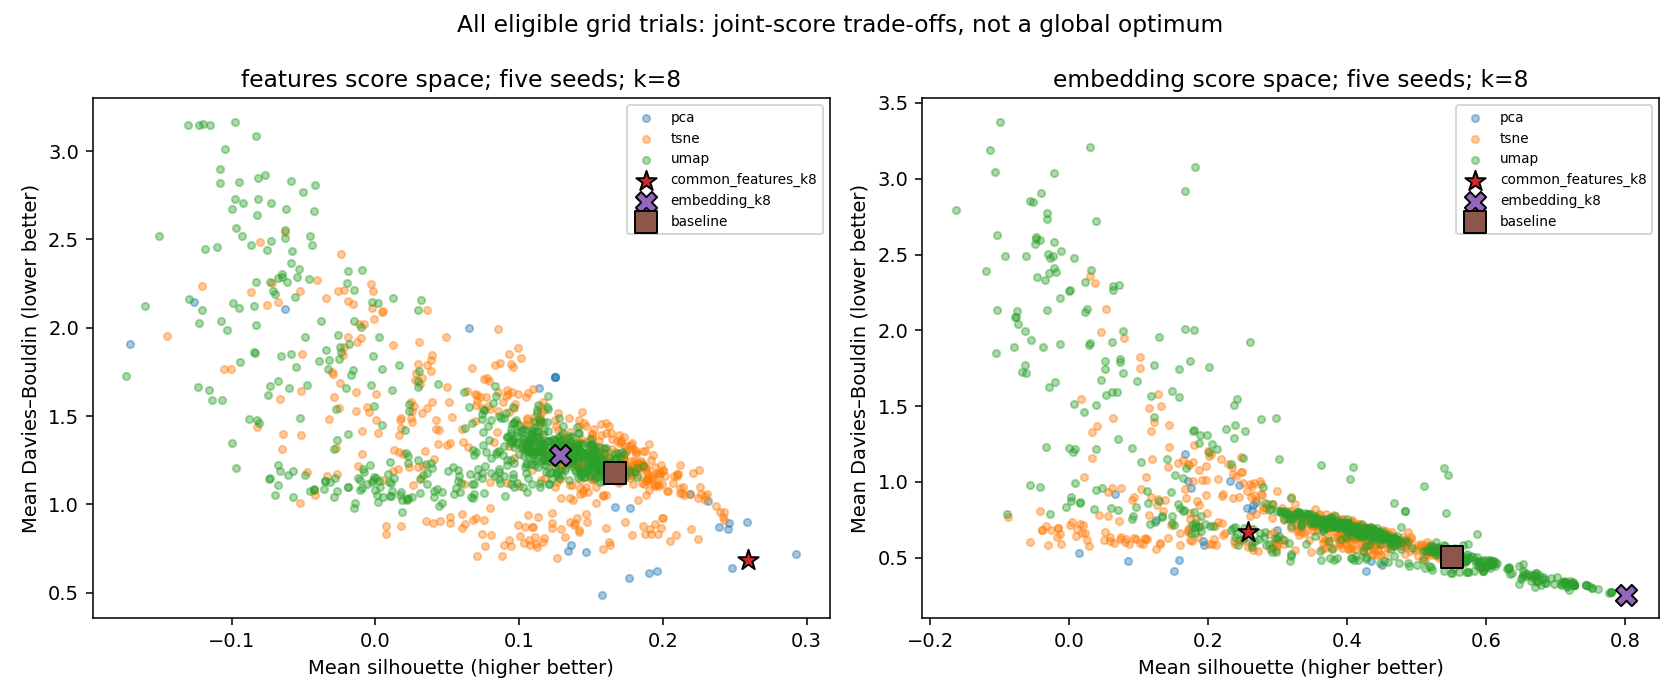

In [5]:
display(study.select_models())
display(study.table("search/family_best_models.csv"))
study.show_figure("search/search_tradeoffs.png")

In [6]:
display(study.table("search/distance_linkage_inventory.csv"))
for role in ["common_features_k8", "embedding_k8"]:
    ranking = study.table(f"search/ranking_{role}.csv")
    display(Markdown(f"### {role}: top joint candidates"))
    display(ranking.head(10))
    geometry = "features" if role == "common_features_k8" else "embedding"
    display(ranking.sort_values(f"silhouette_{geometry}_mean", ascending=False).head(1))
    display(ranking.sort_values(f"davies_bouldin_{geometry}_mean").head(1))

,representation,algorithm,linkage,distance,reduction_distance,configurations,eligible,best_feature_silhouette,lowest_feature_db
0,pca,dbscan,not applicable,cosine,Euclidean linear projection,16,0,0.429259,0.817041
1,pca,dbscan,not applicable,euclidean,Euclidean linear projection,16,0,0.536205,0.569275
2,pca,dbscan,not applicable,manhattan,Euclidean linear projection,16,0,0.074259,2.482767
3,pca,hierarchical,average,chebyshev,Euclidean linear projection,2,2,0.292587,0.720015
4,pca,hierarchical,average,cosine,Euclidean linear projection,2,2,0.166556,0.988294
...,...,...,...,...,...,...,...,...,...
114,umap,hierarchical,ward,euclidean,euclidean,16,16,0.186417,1.151043
115,umap,hierarchical,ward,euclidean,manhattan,16,16,0.170544,1.162932
116,umap,kmeans,not applicable,Euclidean objective,cosine,16,16,0.143089,1.255255
117,umap,kmeans,not applicable,Euclidean objective,euclidean,16,16,0.176079,1.173835


### common_features_k8: top joint candidates

,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
0,c_073540362ecaaa17,5,5,1.0,8,8,4,0.256960,0.000000,0.256960,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""euclidean"", ...",2.0,6.0,8.0,True
1,c_823d157adf23e198,5,5,1.0,8,8,5,0.250840,0.000000,0.250840,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""manhattan"", ...",4.0,5.0,9.0,True
2,c_270de6df6144c04c,5,5,1.0,8,8,3,0.299198,0.000000,0.299198,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""chebyshev"", ...",1.0,10.0,11.0,True
3,c_7362fc096868a7b4,5,5,1.0,8,8,3,0.172483,0.087193,0.094479,...,True,tsne,r_cf99830e94994666,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""single"", ""metric"": ""chebyshev"", ""...",21.0,28.0,49.0,False
4,c_5fd1f0e1f201e4f8,5,5,1.0,8,8,2,0.262240,0.000000,0.262240,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""complete"", ""metric"": ""euclidean"",...",6.0,45.0,51.0,False
5,c_f6d02ef48e373961,5,5,1.0,8,8,5,0.192337,0.000000,0.192337,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""single"", ""metric"": ""chebyshev"", ""...",56.0,4.0,60.0,True
6,c_80e31907c15173ed,5,5,1.0,8,8,4,0.205930,0.134111,0.052035,...,True,tsne,r_00e4f1b83f2212f3,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""single"", ""metric"": ""euclidean"", ""...",38.0,25.0,63.0,False
7,c_3456bde3f7027c6e,5,5,1.0,8,8,2,0.256125,0.000000,0.256125,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""ward"", ""metric"": ""euclidean"", ""n_...",11.0,54.0,65.0,False
8,c_fb38f29c0a786d72,5,5,1.0,8,8,3,0.308403,0.030568,0.275326,...,True,tsne,r_cf99830e94994666,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""single"", ""metric"": ""euclidean"", ""...",23.0,44.0,67.0,False
9,c_10a39e99d673a160,5,5,1.0,8,8,4,0.263897,0.103041,0.082050,...,True,tsne,r_28f2f9aed8b4ec9e,hierarchical,"{""init"": ""random"", ""learning_rate"": 10, ""max_i...","{""linkage"": ""single"", ""metric"": ""euclidean"", ""...",35.0,34.0,69.0,False


,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
2,c_270de6df6144c04c,5,5,1.0,8,8,3,0.299198,0.0,0.299198,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""average"", ""metric"": ""chebyshev"", ...",1.0,10.0,11.0,True


,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
53,c_49352ba255487757,5,5,1.0,8,8,7,0.158079,0.0,0.158079,...,True,pca,r_81b710484643a5c4,hierarchical,"{""n_components"": 0.95, ""svd_solver"": ""full""}","{""linkage"": ""single"", ""metric"": ""manhattan"", ""...",237.0,1.0,238.0,True


### embedding_k8: top joint candidates

,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
0,c_152cbd6e85993337,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,kmeans,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""n_clusters"": 8, ""n_init"": 20}",6.0,6.0,12.0,True
1,c_190352ea0dd7b2c1,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""complete"", ""metric"": ""euclidean"",...",6.0,6.0,12.0,True
2,c_2a9d041d7dd4d41c,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""average"", ""metric"": ""euclidean"", ...",6.0,6.0,12.0,True
3,c_4aebe8ac49e2b2ea,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""ward"", ""metric"": ""euclidean"", ""n_...",6.0,6.0,12.0,True
4,c_a84c8c21f44e3aba,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""single"", ""metric"": ""euclidean"", ""...",6.0,6.0,12.0,True
5,c_bc2b91f26107319d,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""single"", ""metric"": ""manhattan"", ""...",6.0,6.0,12.0,True
6,c_dc7b7875db6a2764,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""complete"", ""metric"": ""manhattan"",...",6.0,6.0,12.0,True
7,c_dd3cc732dfb9095d,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""average"", ""metric"": ""manhattan"", ...",6.0,6.0,12.0,True
8,c_e28969323e8f8170,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""average"", ""metric"": ""chebyshev"", ...",6.0,6.0,12.0,True
9,c_f40a621ab75e88df,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,hierarchical,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""linkage"": ""complete"", ""metric"": ""chebyshev"",...",6.0,6.0,12.0,True


,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
0,c_152cbd6e85993337,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,kmeans,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""n_clusters"": 8, ""n_init"": 20}",6.0,6.0,12.0,True


,candidate_id,seeds,valid_seeds,coverage_min,n_clusters_min,n_clusters_max,singleton_clusters_max,silhouette_embedding_mean,silhouette_embedding_std,silhouette_embedding_min,...,eligible_all_seeds,representation,representation_id,algorithm,representation_parameters,clustering_parameters,silhouette_rank,db_rank,joint_rank_sum,pareto_optimal
0,c_152cbd6e85993337,5,5,1.0,8,8,0,0.800419,0.030982,0.748729,...,True,umap,r_deca05f82c54a9d1,kmeans,"{""metric"": ""cosine"", ""min_dist"": 0.01, ""n_comp...","{""n_clusters"": 8, ""n_init"": 20}",6.0,6.0,12.0,True


## 4. Results at each date with frozen parameters

The representative fit is seed 42. Save all five seeds and pairwise stability. Each selected hierarchical model gets a dendrogram built from its **actual fitted tree**; non-hierarchical models do not get an invented dendrogram. PCA95 trees use all retained dimensions, even though maps show the first two coordinates.

In [7]:
display(study.fit_results())
display(study.table("selected_seed_stability.csv"))
display(study.table("cluster_surrogate_fidelity.csv"))

,candidate_id,decision_date,seed,sector_ari,sector_nmi,n_clusters,noise_count,coverage,singleton_clusters,score_status,silhouette_embedding,davies_bouldin_embedding,silhouette_features,davies_bouldin_features
0,c_073540362ecaaa17,2025-06-30,42,0.084642,0.383498,8,0,1.00000,4,valid,0.256960,0.672614,0.259235,0.683958
1,c_073540362ecaaa17,2025-12-31,42,0.220167,0.462077,8,0,1.00000,2,valid,0.402785,0.585267,0.367925,0.702833
2,c_073540362ecaaa17,2026-06-30,42,0.228439,0.509813,8,0,1.00000,4,valid,0.415098,0.472503,0.408308,0.496284
3,c_152cbd6e85993337,2025-06-30,42,0.236396,0.533640,8,0,1.00000,0,valid,0.828635,0.218273,0.128598,1.277982
4,c_152cbd6e85993337,2025-12-31,42,0.289647,0.546757,8,0,1.00000,0,valid,0.771384,0.243476,0.207734,1.032298
5,c_152cbd6e85993337,2026-06-30,42,0.291634,0.575128,8,0,1.00000,0,valid,0.747517,0.309412,0.227843,1.128289
6,c_190352ea0dd7b2c1,2025-06-30,42,0.236396,0.533640,8,0,1.00000,0,valid,0.828635,0.218273,0.128598,1.277982
7,c_190352ea0dd7b2c1,2025-12-31,42,0.266923,0.556850,8,0,1.00000,0,valid,0.730976,0.293704,0.207731,1.023669
8,c_190352ea0dd7b2c1,2026-06-30,42,0.284004,0.569106,8,0,1.00000,0,valid,0.740055,0.306119,0.212791,1.144877
9,c_270de6df6144c04c,2025-06-30,42,0.101755,0.407642,8,0,1.00000,3,valid,0.299198,0.682701,0.292587,0.720015


,candidate_id,decision_date,seed_a,seed_b,common_coverage,ari,nmi
0,c_073540362ecaaa17,2025-06-30,42,43,1.00000,1.0,1.0
1,c_073540362ecaaa17,2025-06-30,42,44,1.00000,1.0,1.0
2,c_073540362ecaaa17,2025-06-30,42,45,1.00000,1.0,1.0
3,c_073540362ecaaa17,2025-06-30,42,46,1.00000,1.0,1.0
4,c_073540362ecaaa17,2025-06-30,43,44,1.00000,1.0,1.0
...,...,...,...,...,...,...,...
535,c_ff86aac25ddcaaf4,2026-06-30,43,45,0.95122,1.0,1.0
536,c_ff86aac25ddcaaf4,2026-06-30,43,46,0.95122,1.0,1.0
537,c_ff86aac25ddcaaf4,2026-06-30,44,45,0.95122,1.0,1.0
538,c_ff86aac25ddcaaf4,2026-06-30,44,46,0.95122,1.0,1.0


,candidate_id,decision_date,in_sample_accuracy,oof_accuracy,minimum_cluster_size,oof_status,meaning,class_mapping,shap_shape,shap_max_additivity_error,shap_additivity_atol
0,c_073540362ecaaa17,2025-06-30,1.00000,NaN,1,not estimable: singleton cluster,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000002,0.0001
1,c_073540362ecaaa17,2025-12-31,1.00000,NaN,1,not estimable: singleton cluster,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000002,0.0001
2,c_073540362ecaaa17,2026-06-30,0.97561,NaN,1,not estimable: singleton cluster,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000003,0.0001
3,c_152cbd6e85993337,2025-06-30,1.00000,0.560976,3,estimated,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000002,0.0001
4,c_152cbd6e85993337,2025-12-31,1.00000,0.560976,2,estimated,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000003,0.0001
5,c_152cbd6e85993337,2026-06-30,1.00000,0.536585,2,estimated,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000003,0.0001
6,c_4f80a40f7dda0468,2025-06-30,1.00000,0.536585,2,estimated,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000001,0.0001
7,c_4f80a40f7dda0468,2025-12-31,1.00000,NaN,1,not estimable: singleton cluster,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000002,0.0001
8,c_4f80a40f7dda0468,2026-06-30,1.00000,0.731707,2,estimated,surrogate fidelity to full-snapshot pseudo-lab...,"{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': ...","[41, 10, 8]",0.000002,0.0001


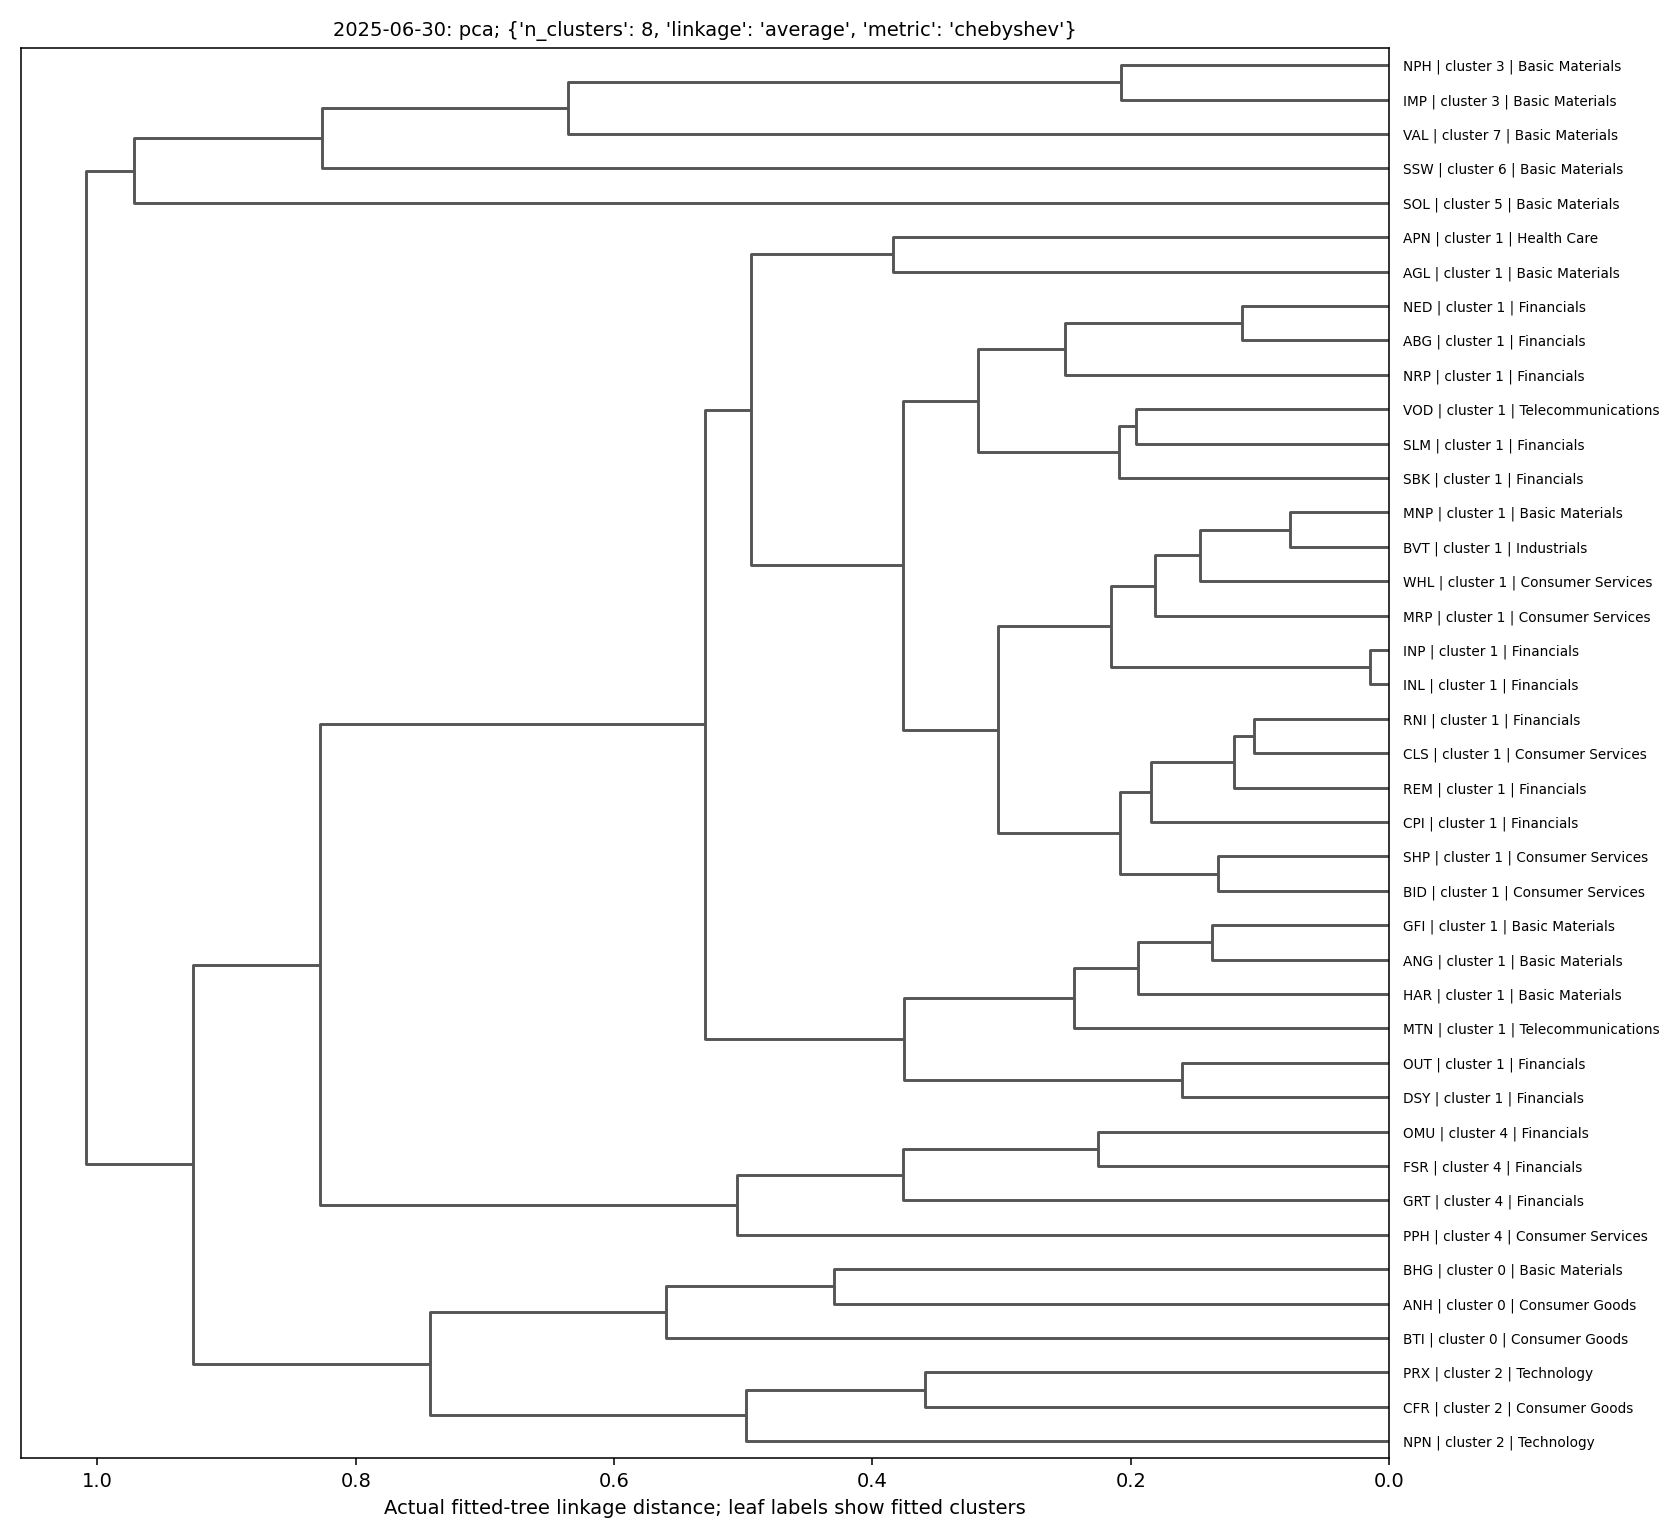

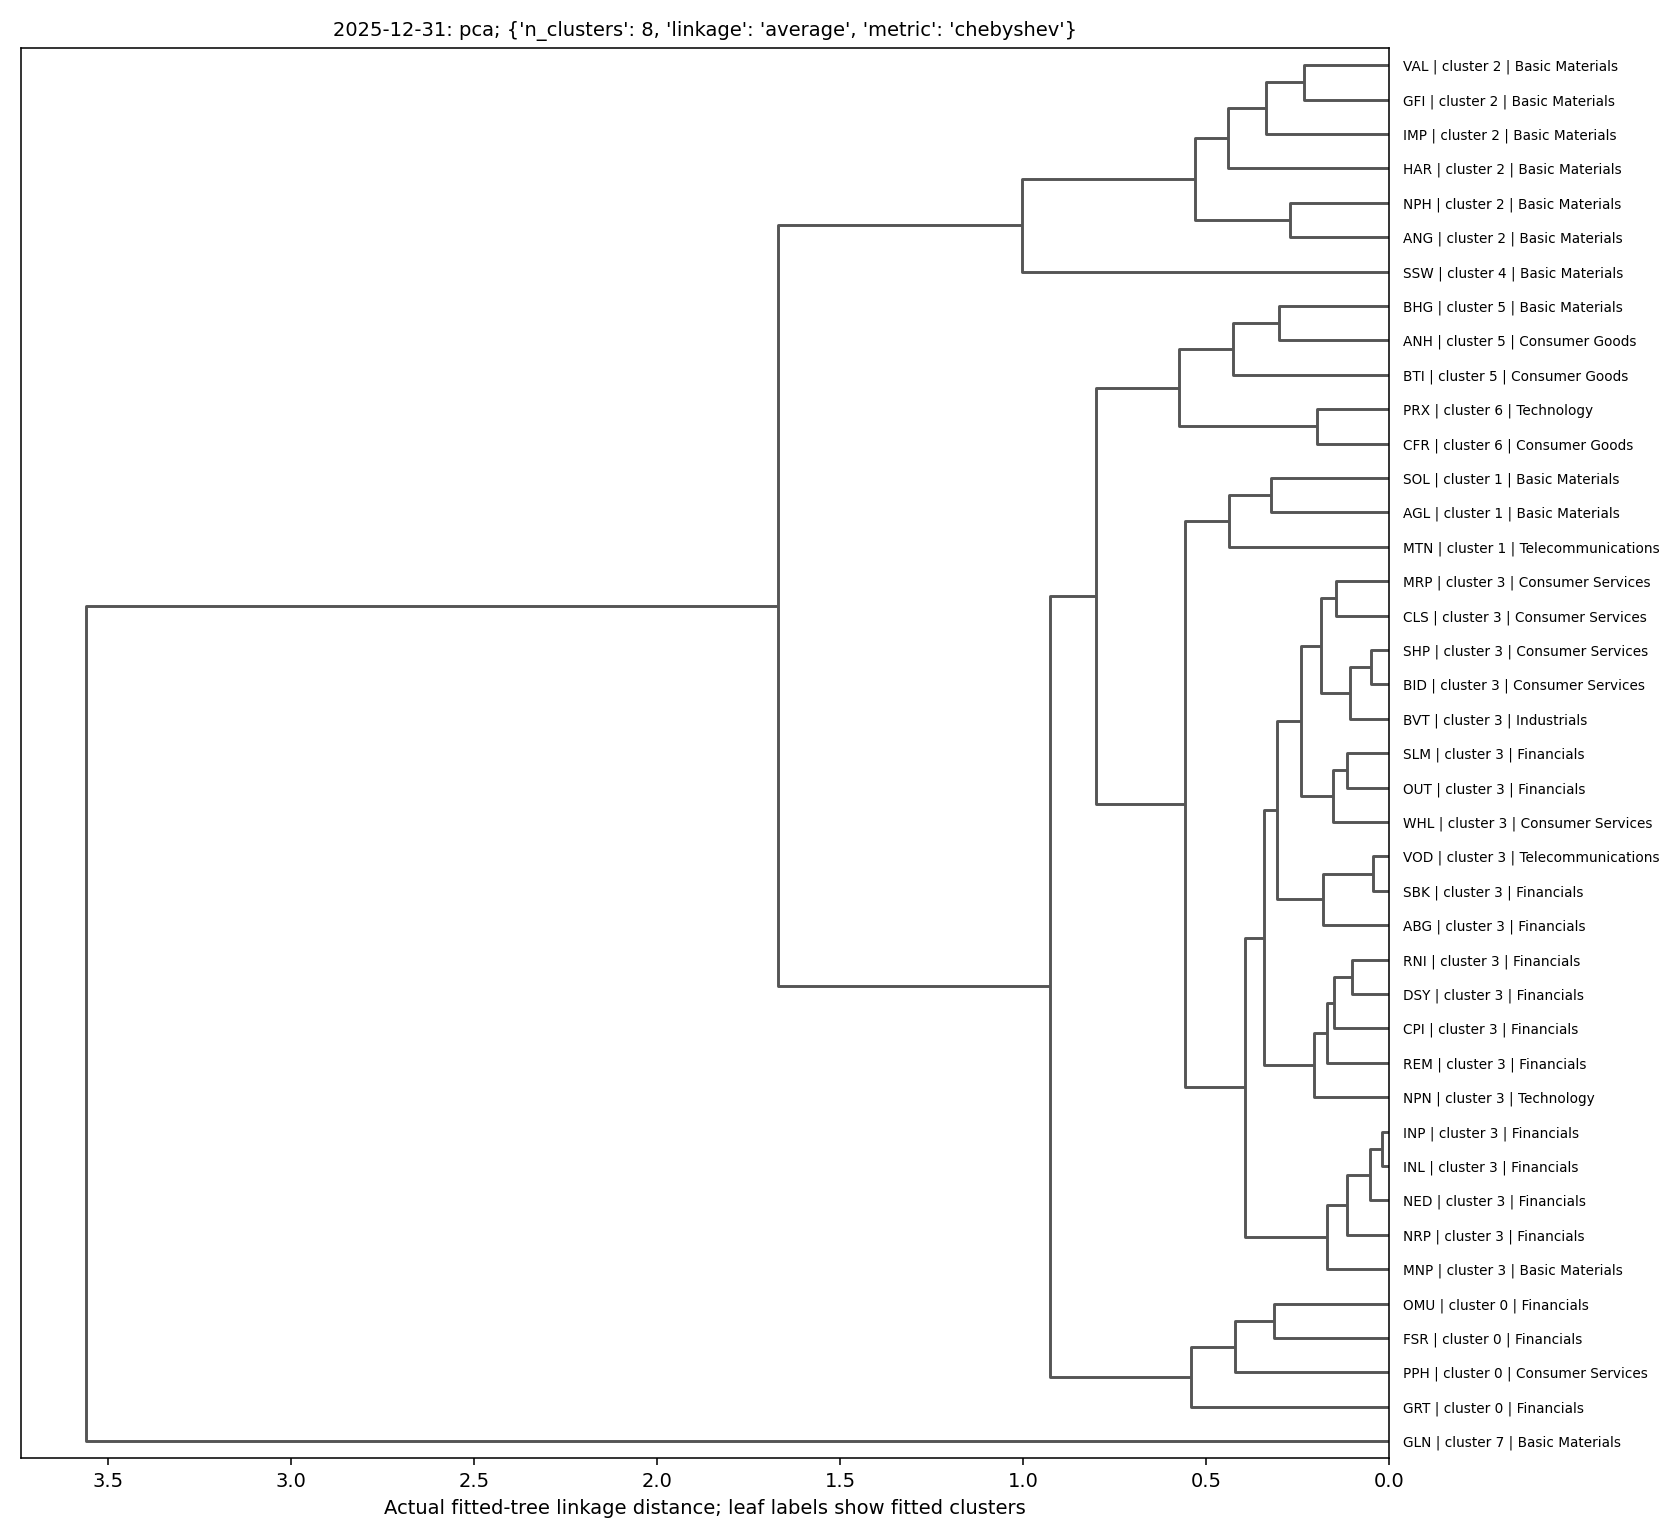

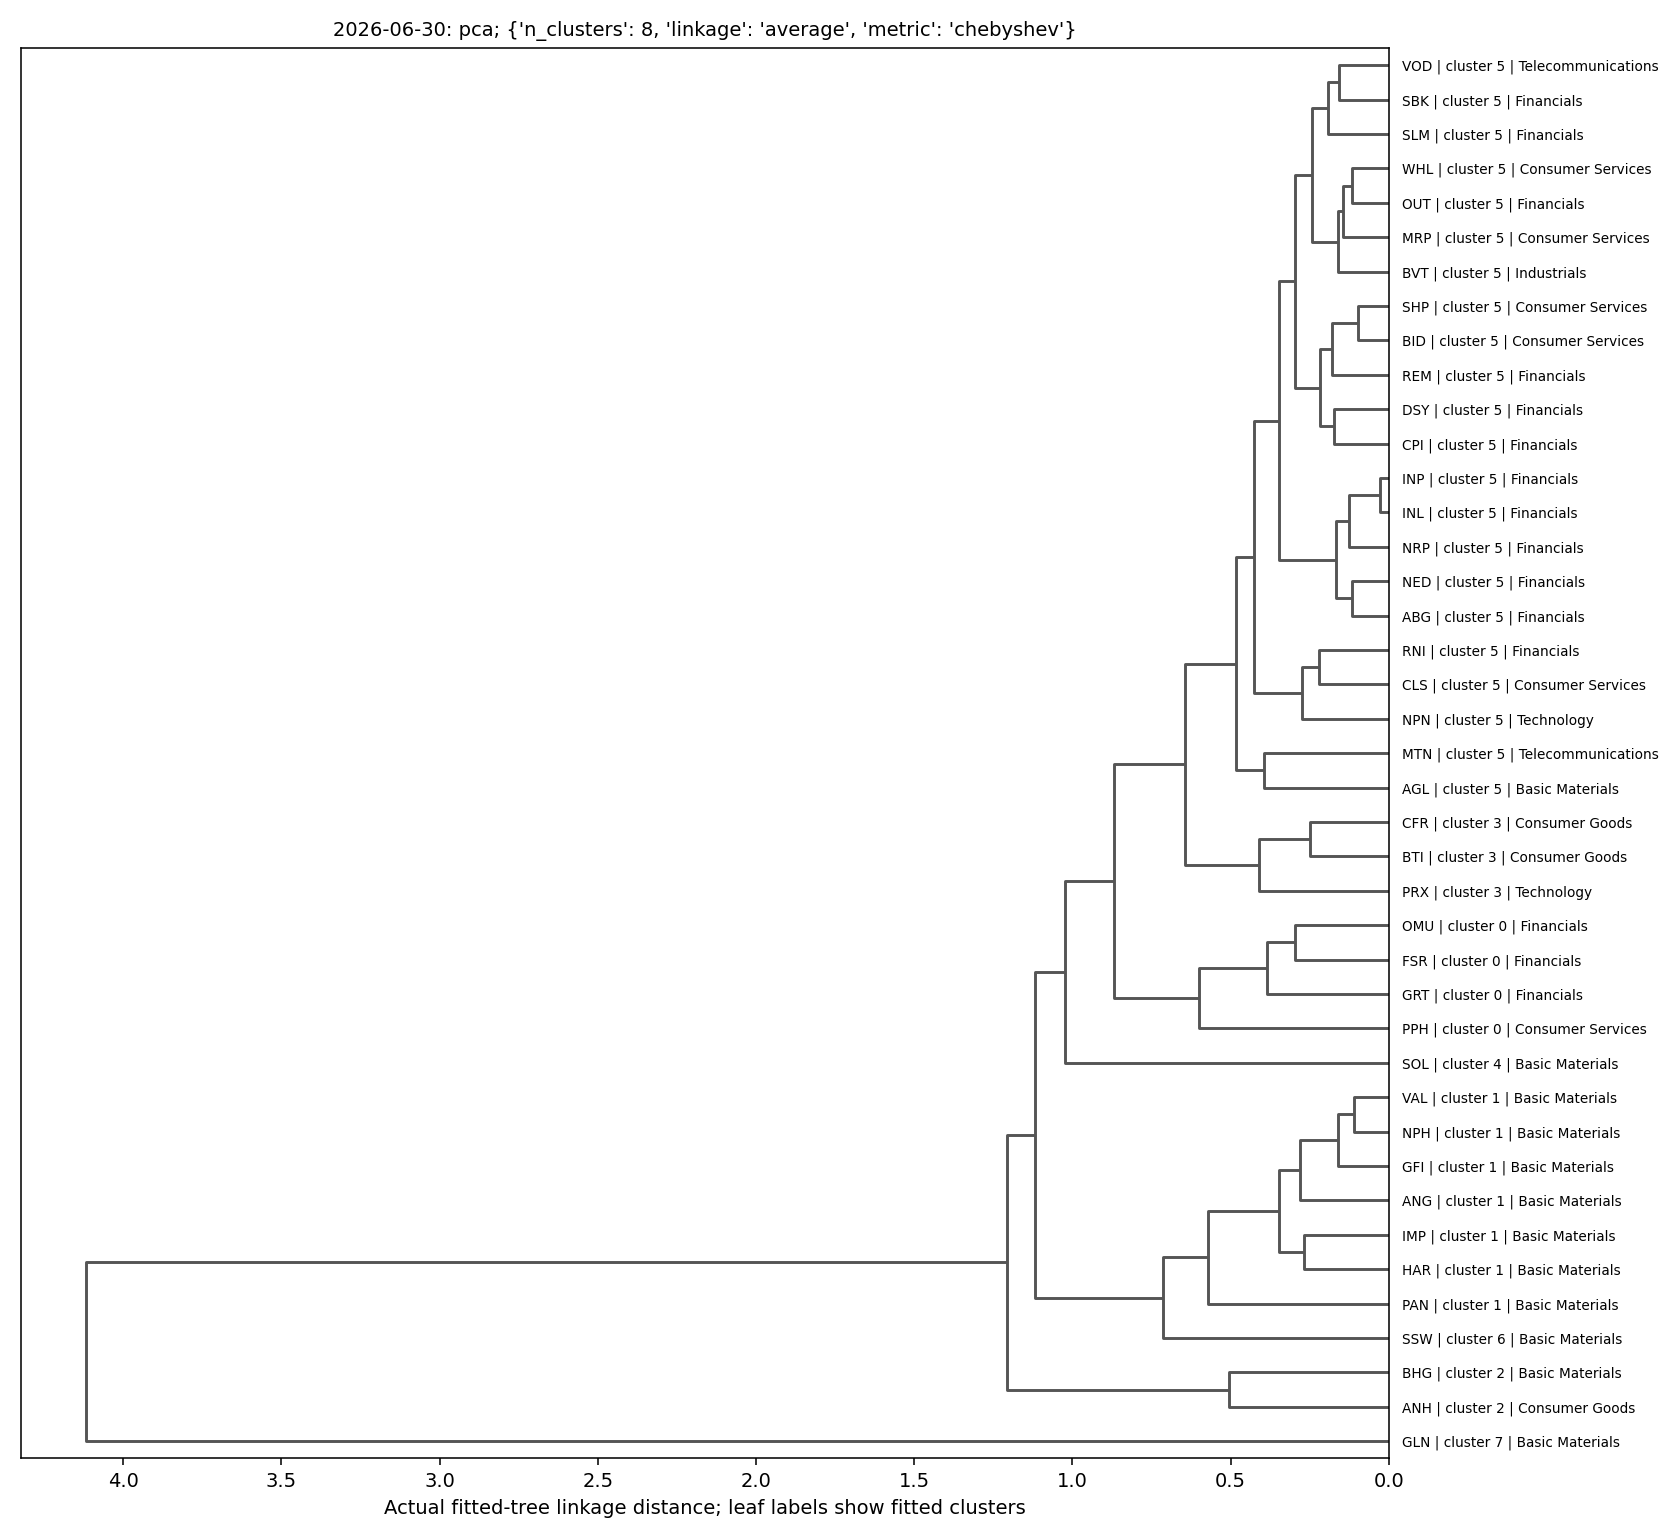

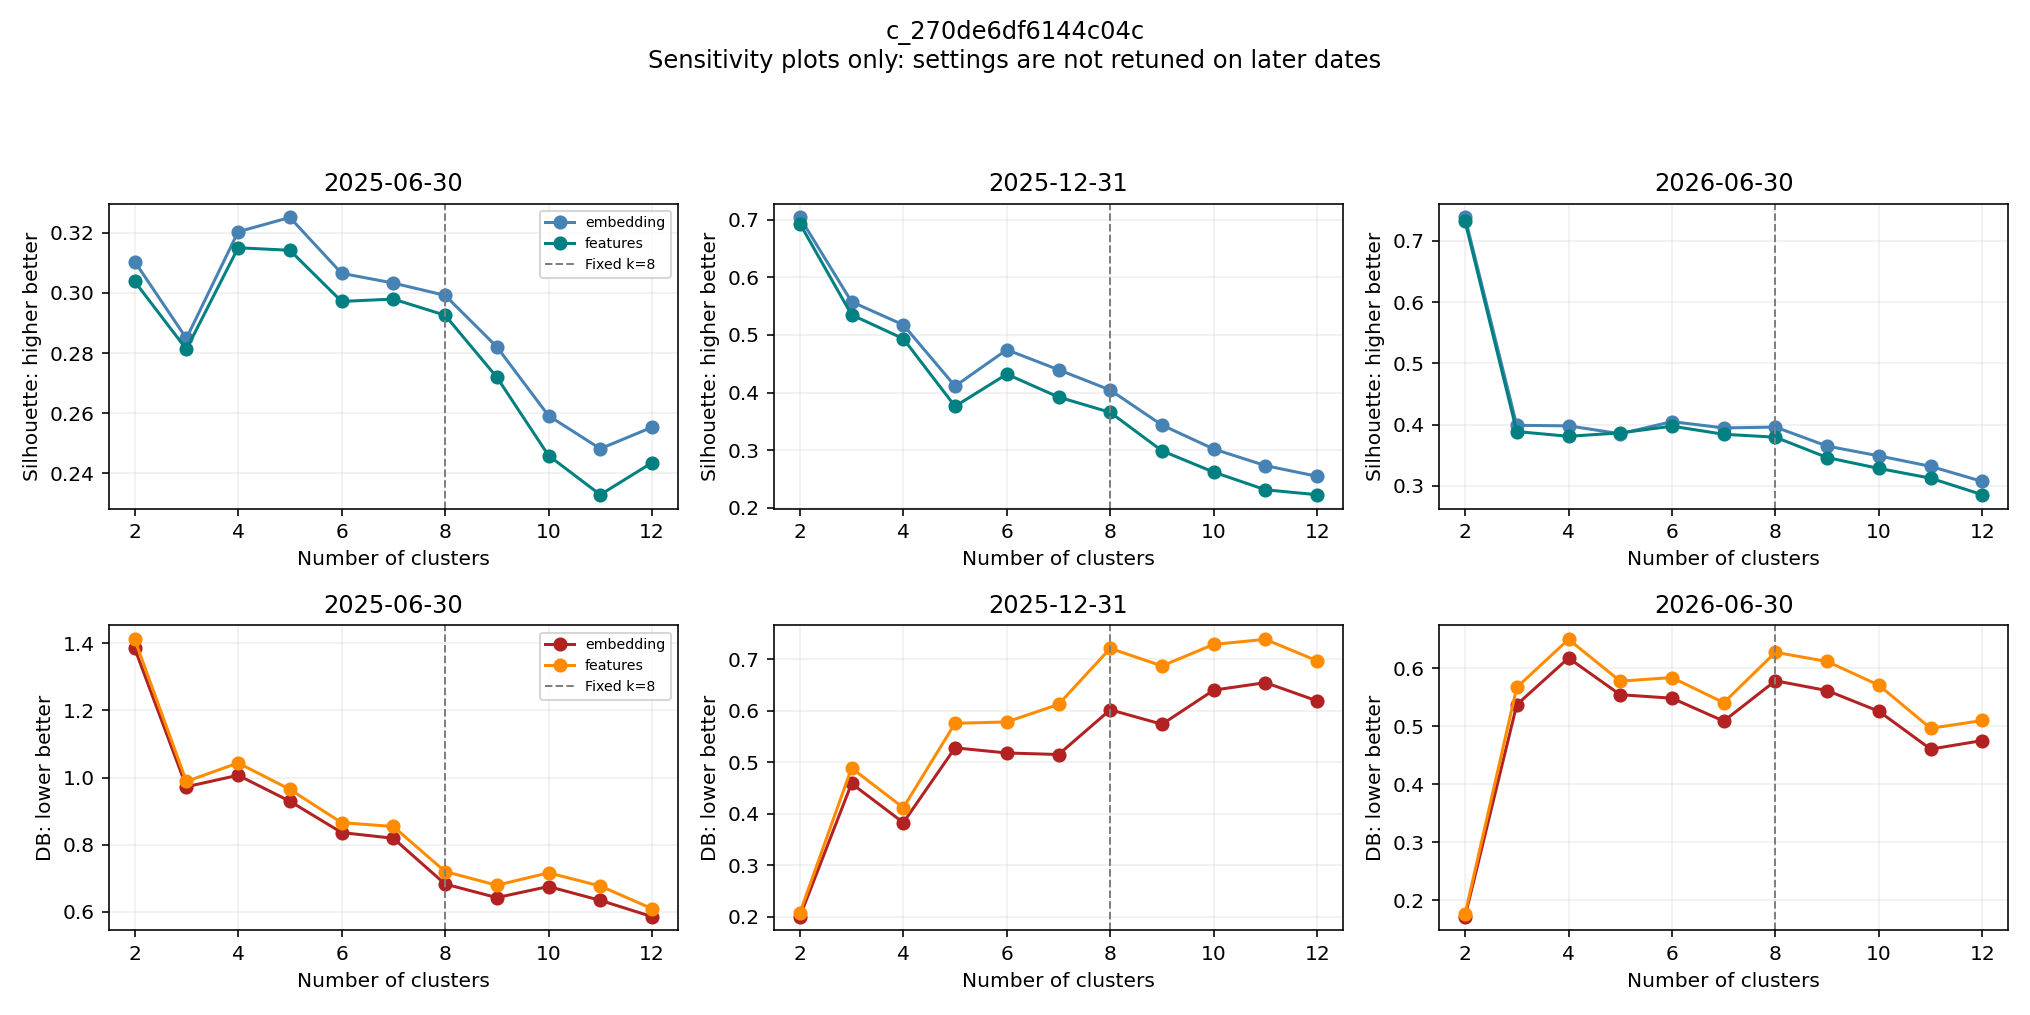

In [8]:
# Show a complete three-date dendrogram series for the best common-feature hierarchical model.
# The original t-SNE/average-Manhattan baseline remains separately available.
role = "features_pca_hierarchical"
CID = study.choices.get(role, study.choices["baseline"])
for date in study.config["dates"]:
    study.show_figure(f"models/{CID}/{date}/dendrogram.png")
study.show_figure(f"models/{CID}/k_diagnostics.png")

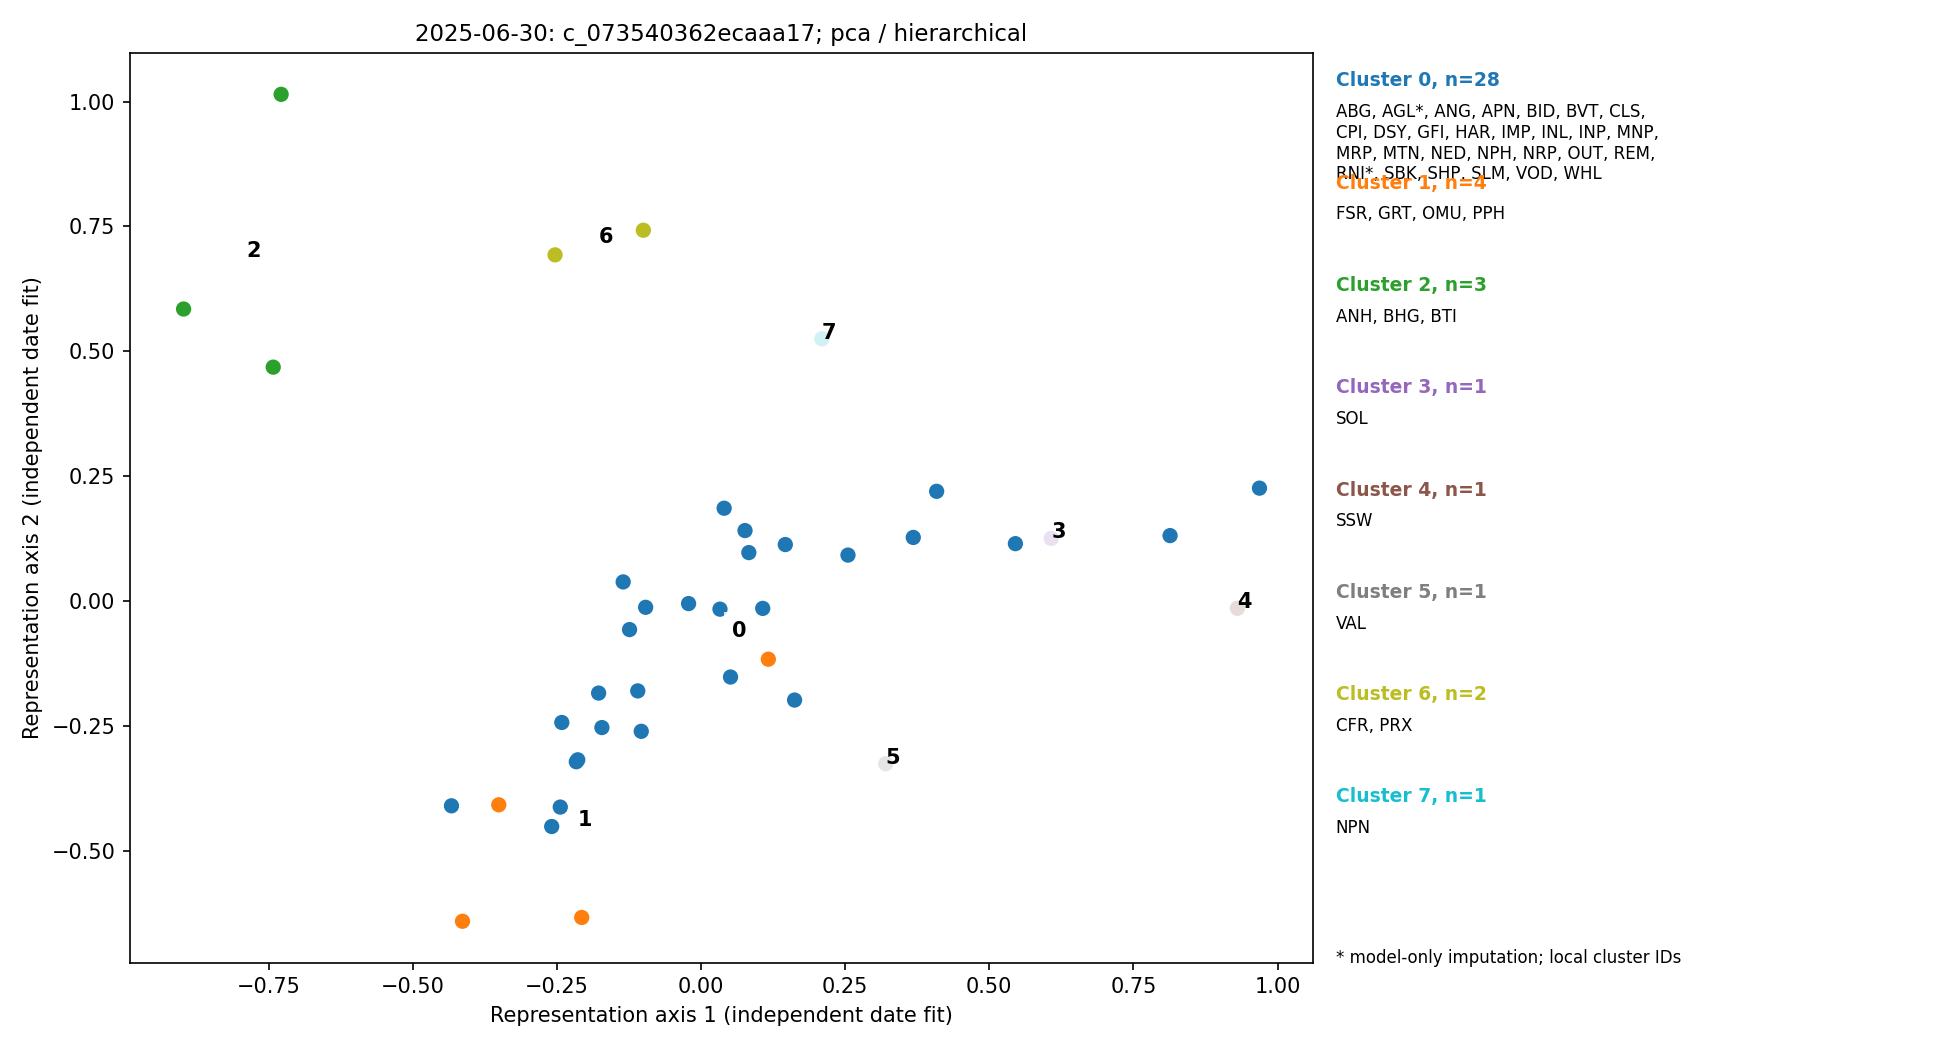

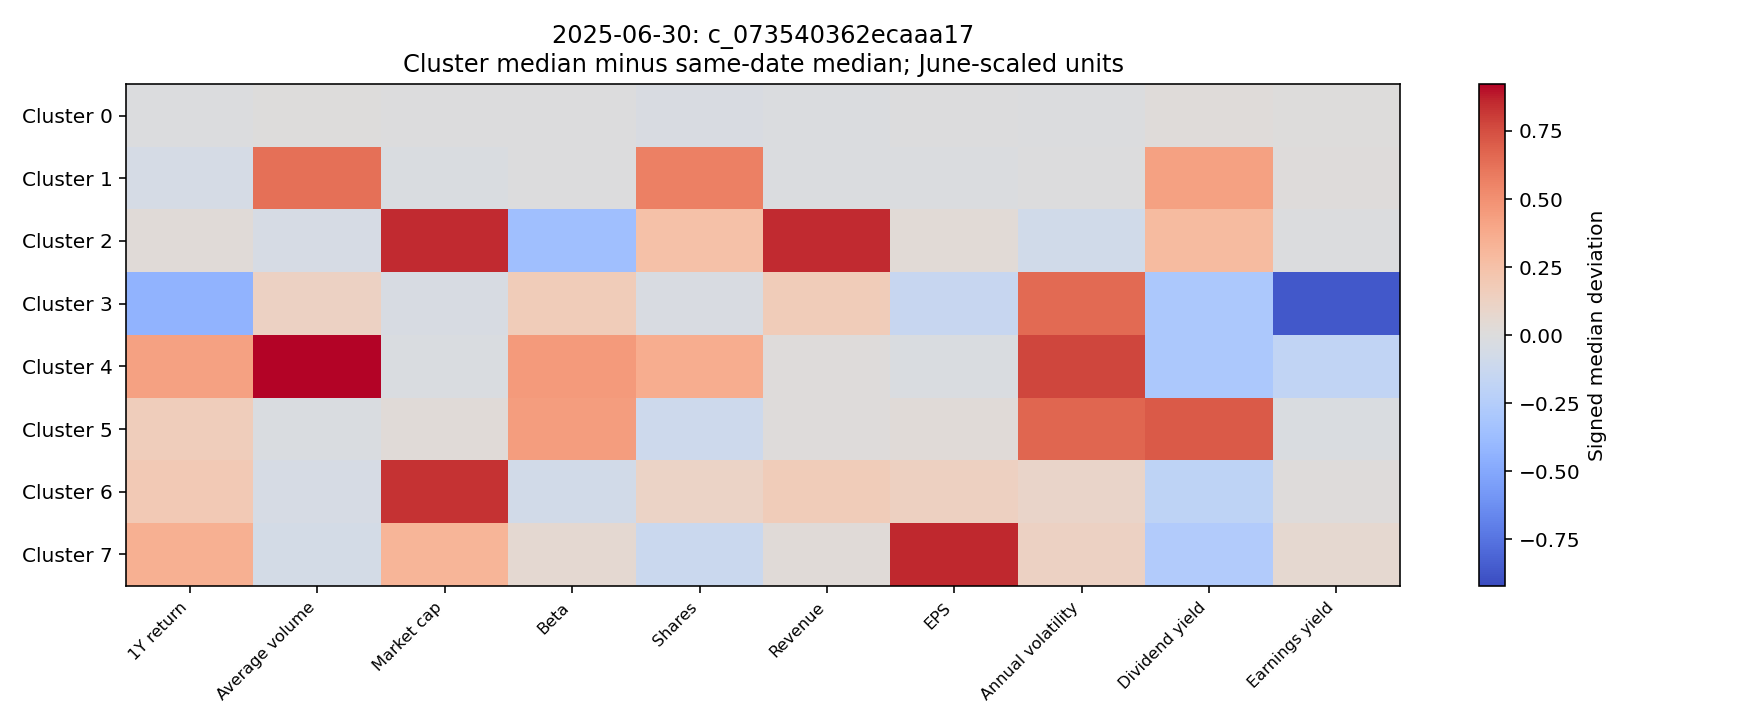

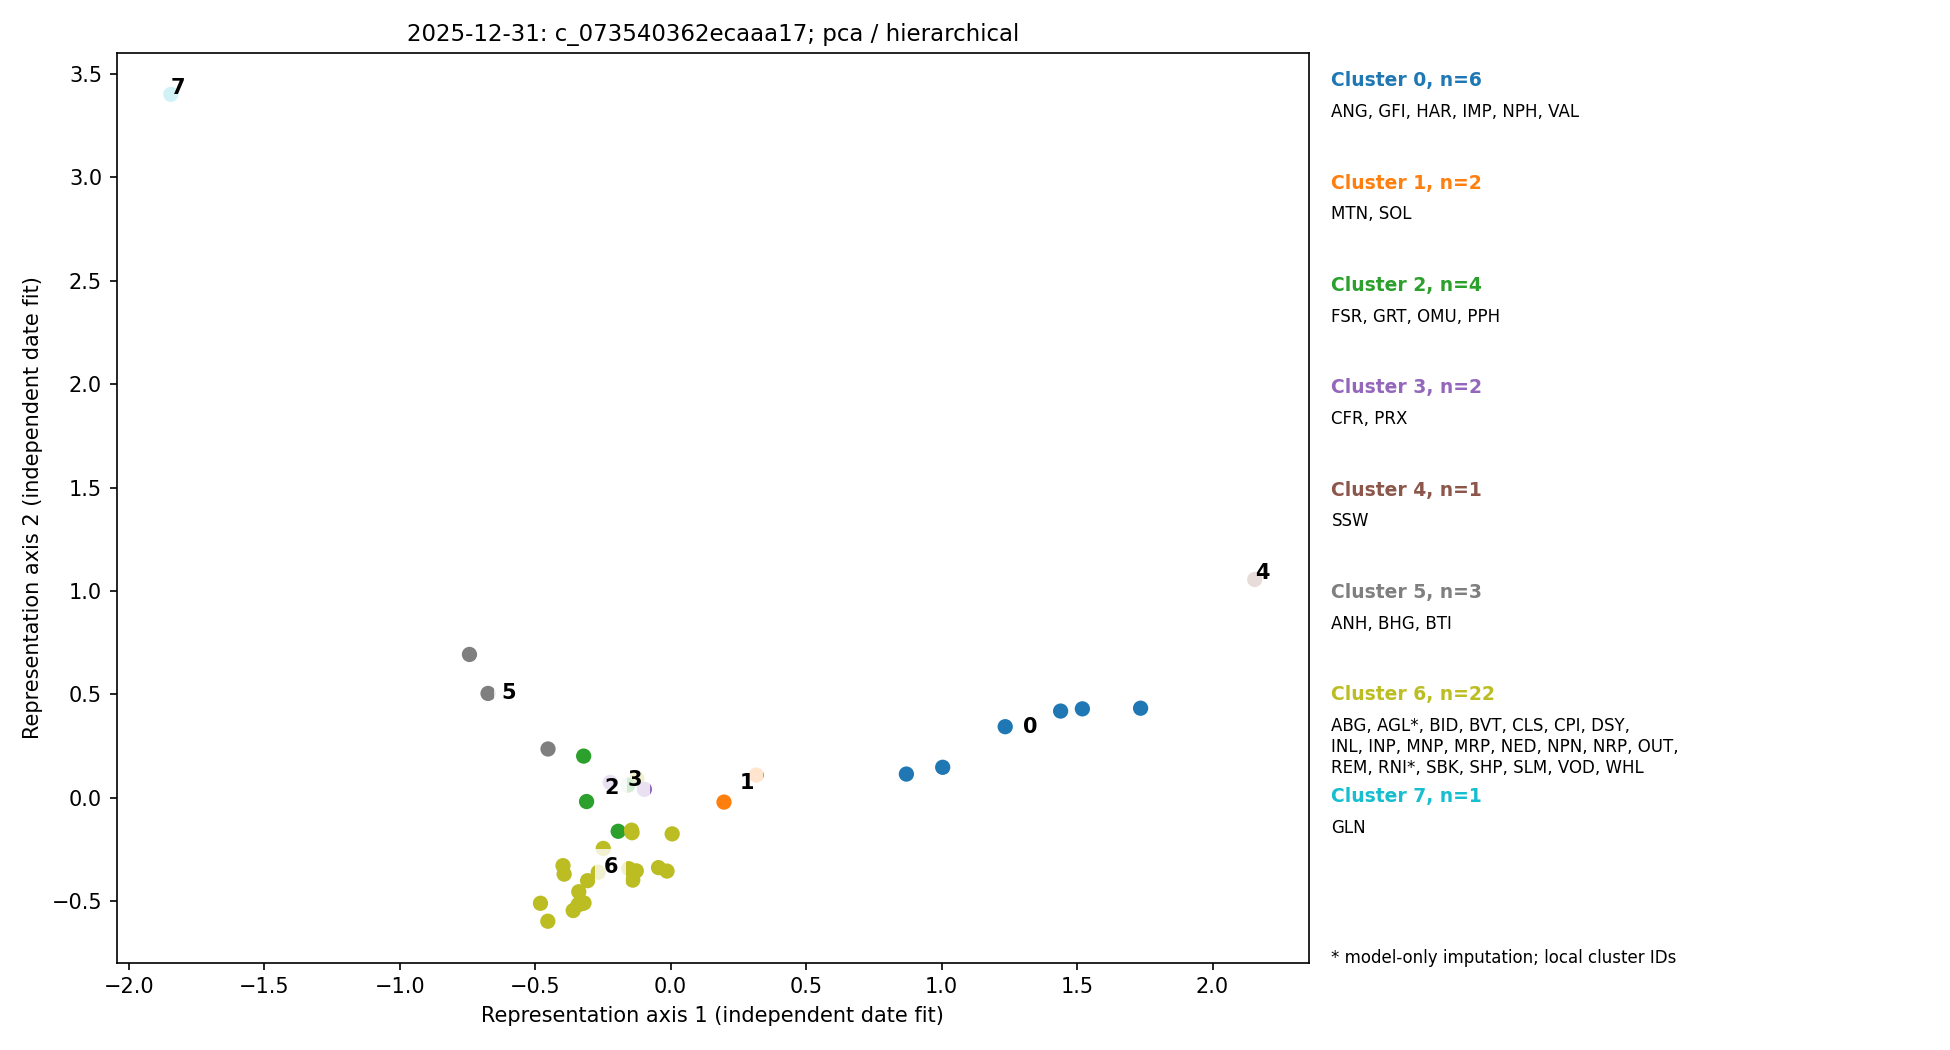

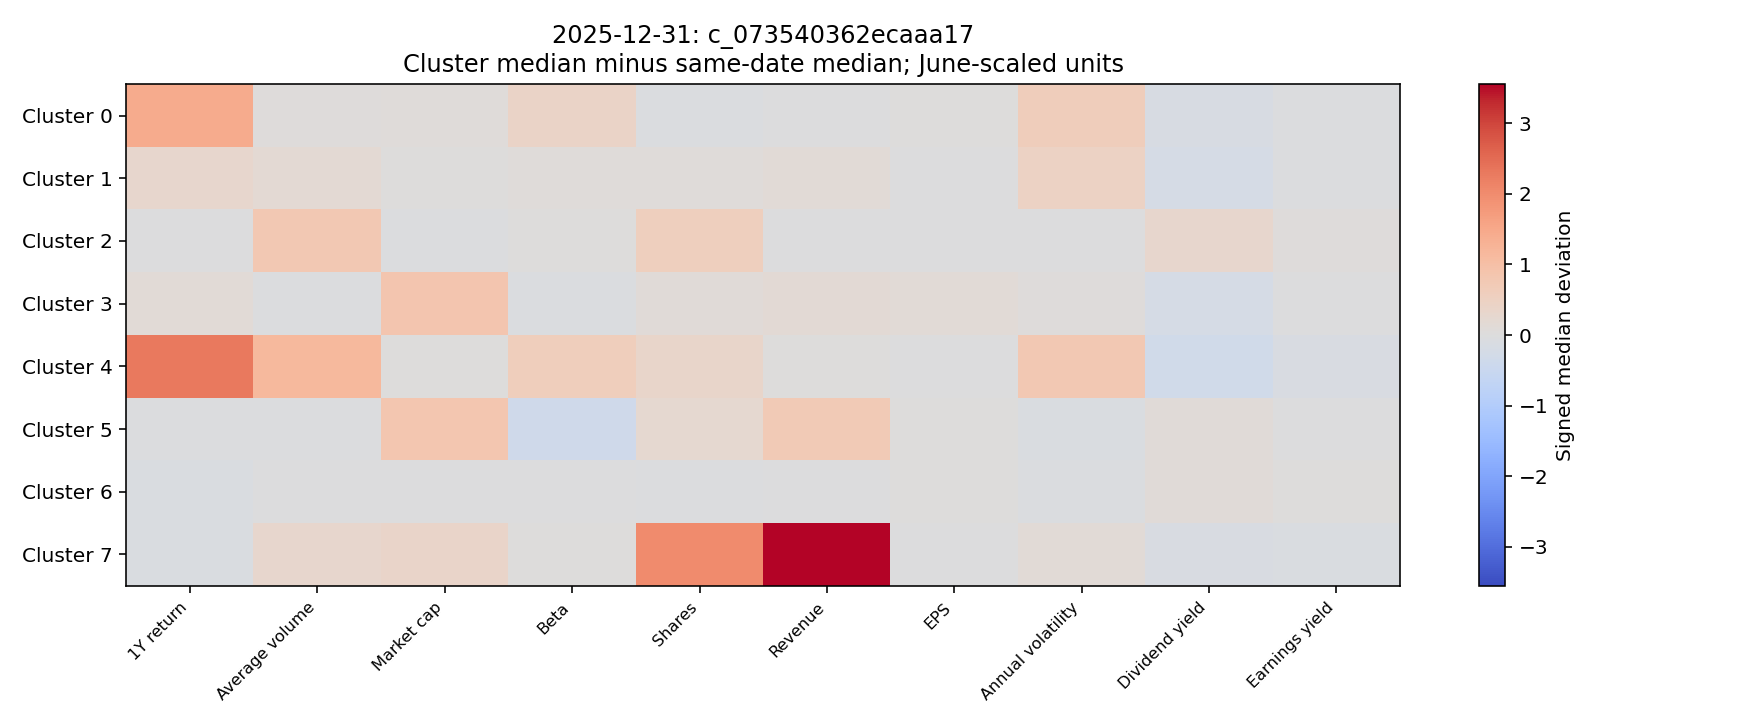

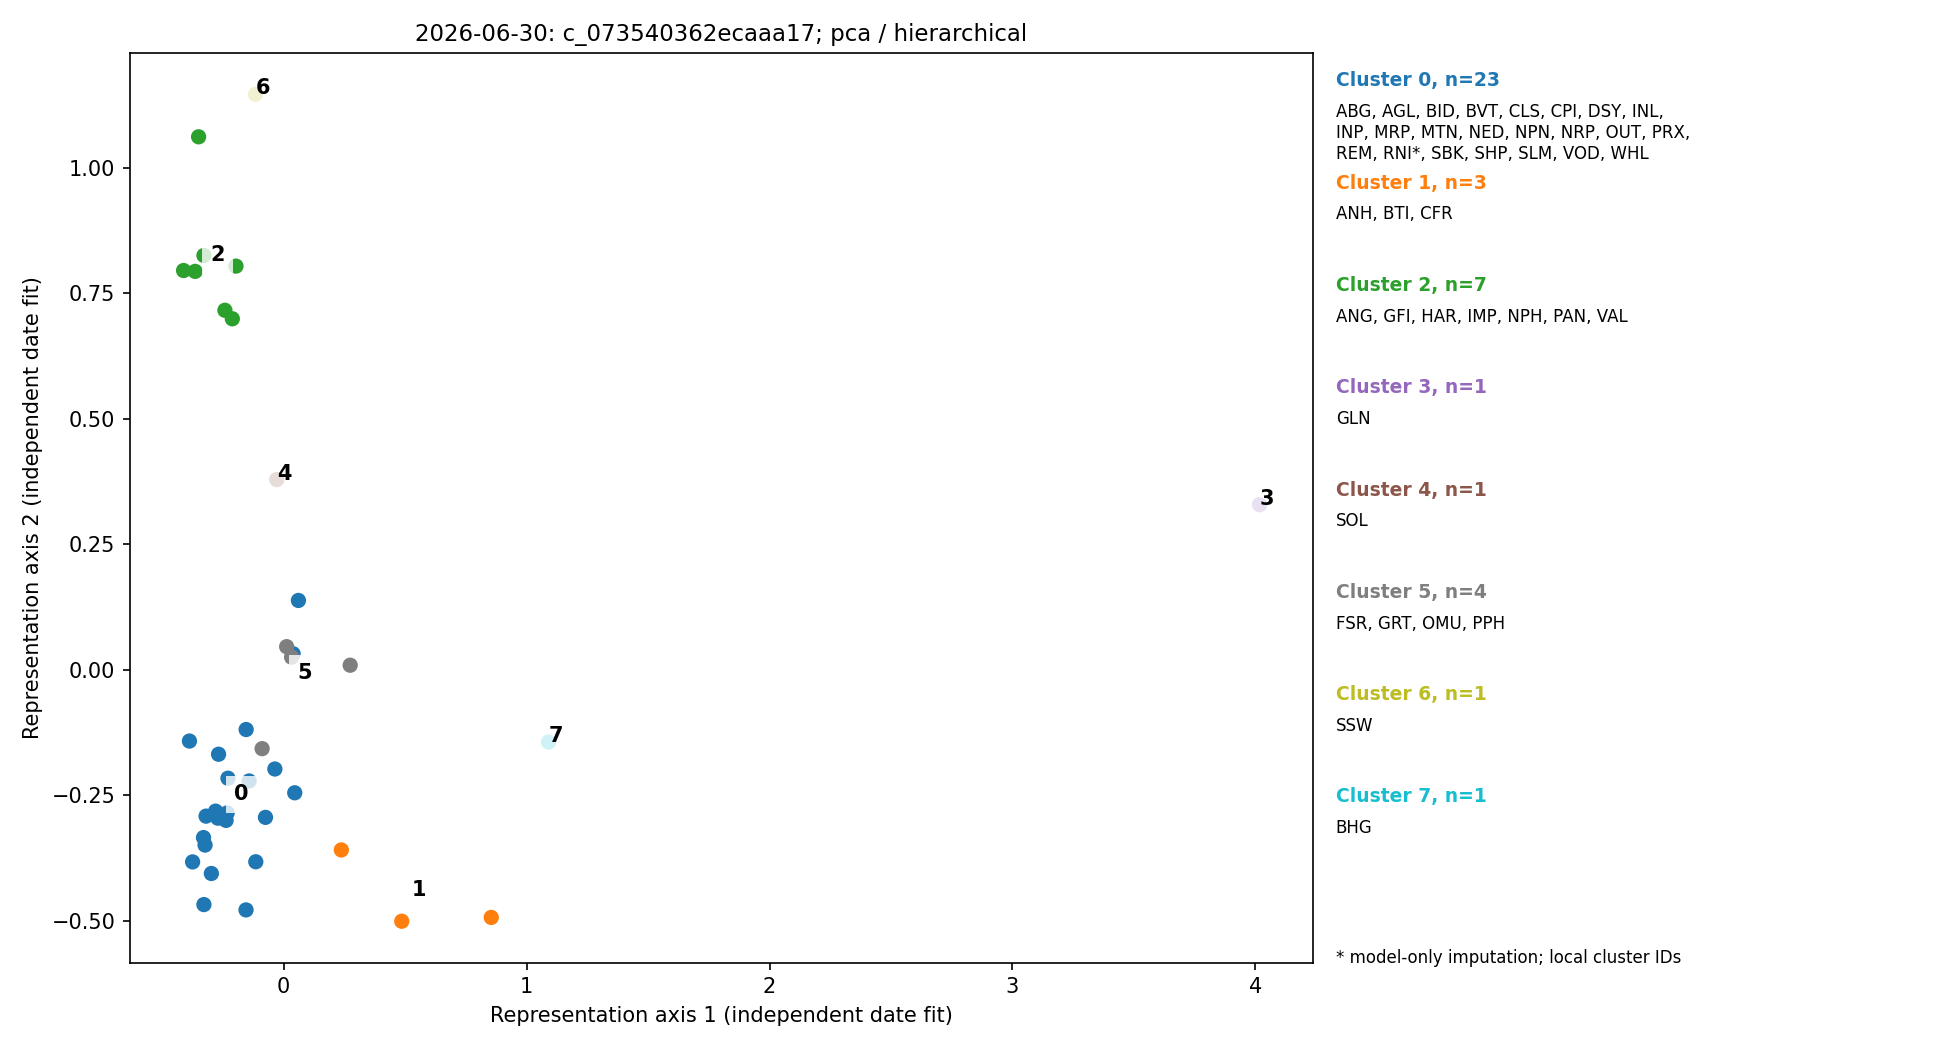

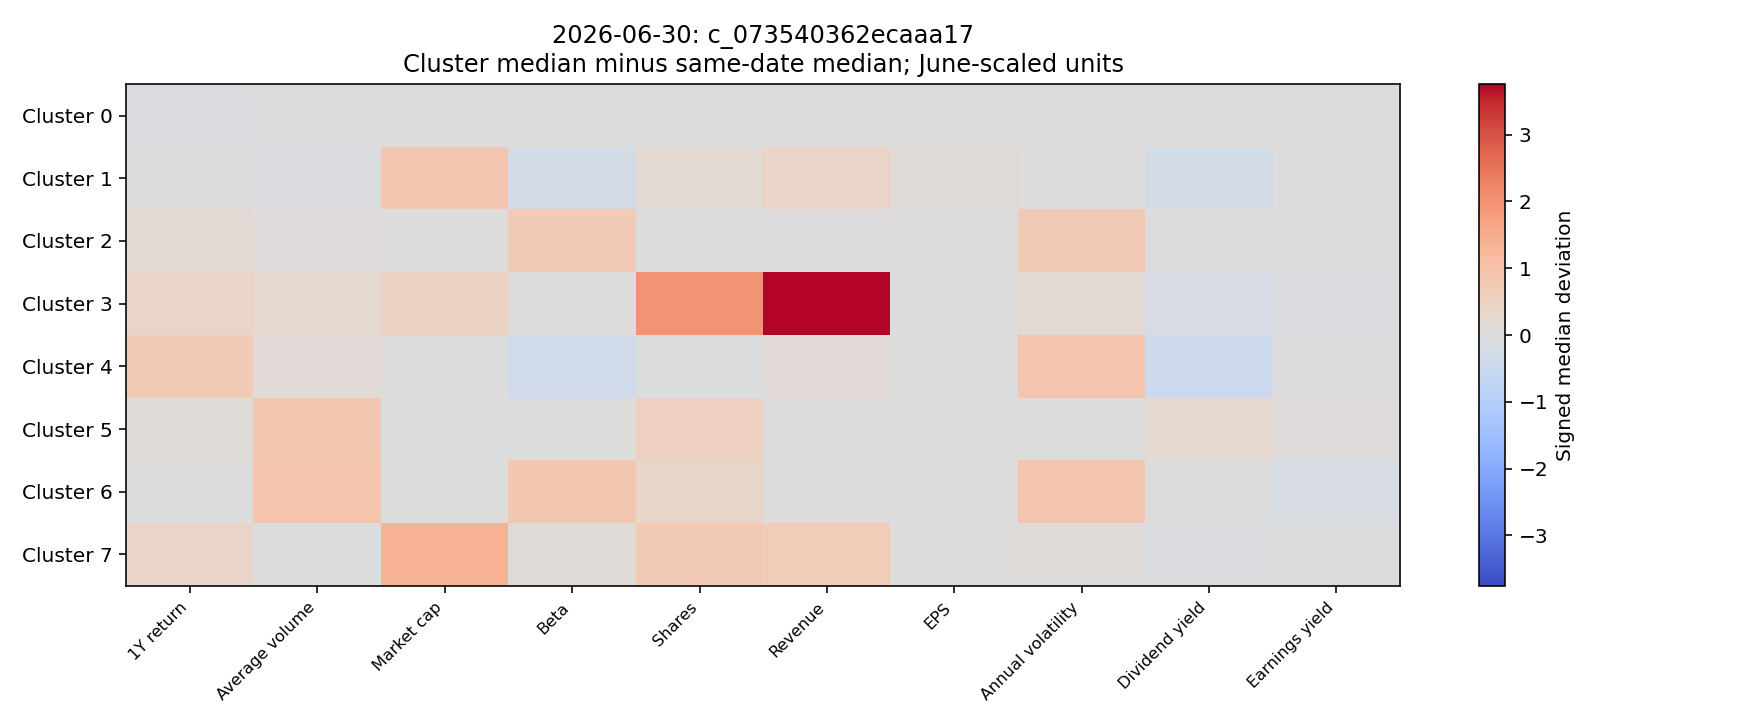

In [9]:
# View the primary selected model's membership and feature profile at each date.
PRIMARY = study.choices["common_features_k8"]
for date in study.config["dates"]:
    study.show_figure(f"models/{PRIMARY}/{date}/cluster_map.png")
    study.show_figure(f"models/{PRIMARY}/{date}/feature_profile.png")

## 5. Stable/shifted instruments, sector divergence and descriptive outlier statistics

Align arbitrary labels with Hungarian maximum Jaccard on common members. Sorted labels and a deterministic solver make the procedure reproducible; zero-overlap matches get fresh IDs. Compare with maximum-overlap alignment and direct baseline-to-current alignment. Only all-three-date members receive a three-date stable/shifted status. Entries and exits are separate events.

The individual geometric statistic is D? = (z? ? z?)? S?? (z? ? z?), with p=2 and unbiased same-date covariance. **There is no n multiplier.** Compare it descriptively with p(n?1)/(n?p) F?.??(p,n?p). This mean-T? F formula is not the individual-distance null calibration. We also record an internal Beta reference as a sensitivity. Singular/ill-conditioned covariance means no screen is estimable. Data-adaptive t-SNE/UMAP coordinates do not justify a confirmed significance claim.

A representative-seed screen flag supported by at least 3/5 estimable seeds is labelled multi-seed-supported. It is still a **candidate**, not a confirmed outlier. Three-date flags distinguish emerging, persistent, transient, resolving and recurring histories; missing membership/screen means ineligible.

A singleton, geometric extreme and sector-divergent firm are separate cases. Sector divergence compares a firm with the leave-one-out majority sector of its cluster; ties and singletons remain unresolved. An additional maximum-overlap cluster/sector mapping is explicitly contextual. The legacy sectors are not independently verified historic ground truth.

,role,candidate_id,status,stable_all_three,shifted_all_three,membership_gaps,screen_candidates,multi_seed_supported_candidates,confirmed_outliers,sector_divergences
0,baseline,c_4f80a40f7dda0468,completed descriptive review,21,18,4,0,0,0,40
1,common_features_k8,c_073540362ecaaa17,completed descriptive review,29,10,4,5,5,0,48
2,embedding_k8,c_152cbd6e85993337,completed descriptive review,19,20,4,0,0,0,37


,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ABG,0.0,0.0,0.0,True,stable all three,False,False
1,AGL,0.0,0.0,0.0,True,stable all three,False,False
2,BHG,2.0,2.0,2.0,True,stable all three,False,False
3,BID,0.0,0.0,0.0,True,stable all three,False,False
4,BVT,0.0,0.0,0.0,True,stable all three,False,False
5,CFR,6.0,6.0,6.0,True,stable all three,False,False
6,CLS,0.0,0.0,0.0,True,stable all three,False,False
7,CPI,0.0,0.0,0.0,True,stable all three,False,False
8,DSY,0.0,0.0,0.0,True,stable all three,False,False
9,FSR,1.0,1.0,1.0,True,stable all three,False,False


,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ANG,0.0,5.0,5.0,True,shifted at least once,True,True
1,ANH,2.0,2.0,6.0,True,shifted at least once,True,True
2,BTI,2.0,2.0,6.0,True,shifted at least once,True,True
3,GFI,0.0,5.0,5.0,True,shifted at least once,True,True
4,HAR,0.0,5.0,5.0,True,shifted at least once,True,True
5,IMP,0.0,5.0,5.0,True,shifted at least once,True,True
6,MTN,0.0,3.0,0.0,True,shifted at least once,False,False
7,NPH,0.0,5.0,5.0,True,shifted at least once,True,True
8,NPN,7.0,0.0,0.0,True,shifted at least once,True,True
9,PRX,6.0,6.0,0.0,True,shifted at least once,True,True


,before,after,ticker,membership_event,cluster_before,cluster_after,cluster_changed
4,2025-06-30,2025-12-31,APN,exit,0.0,NaN,NaN
15,2025-06-30,2025-12-31,GLN,entry,NaN,8.0,NaN
62,2025-12-31,2026-06-30,MNP,exit,0.0,NaN,NaN
71,2025-12-31,2026-06-30,PAN,entry,NaN,5.0,NaN


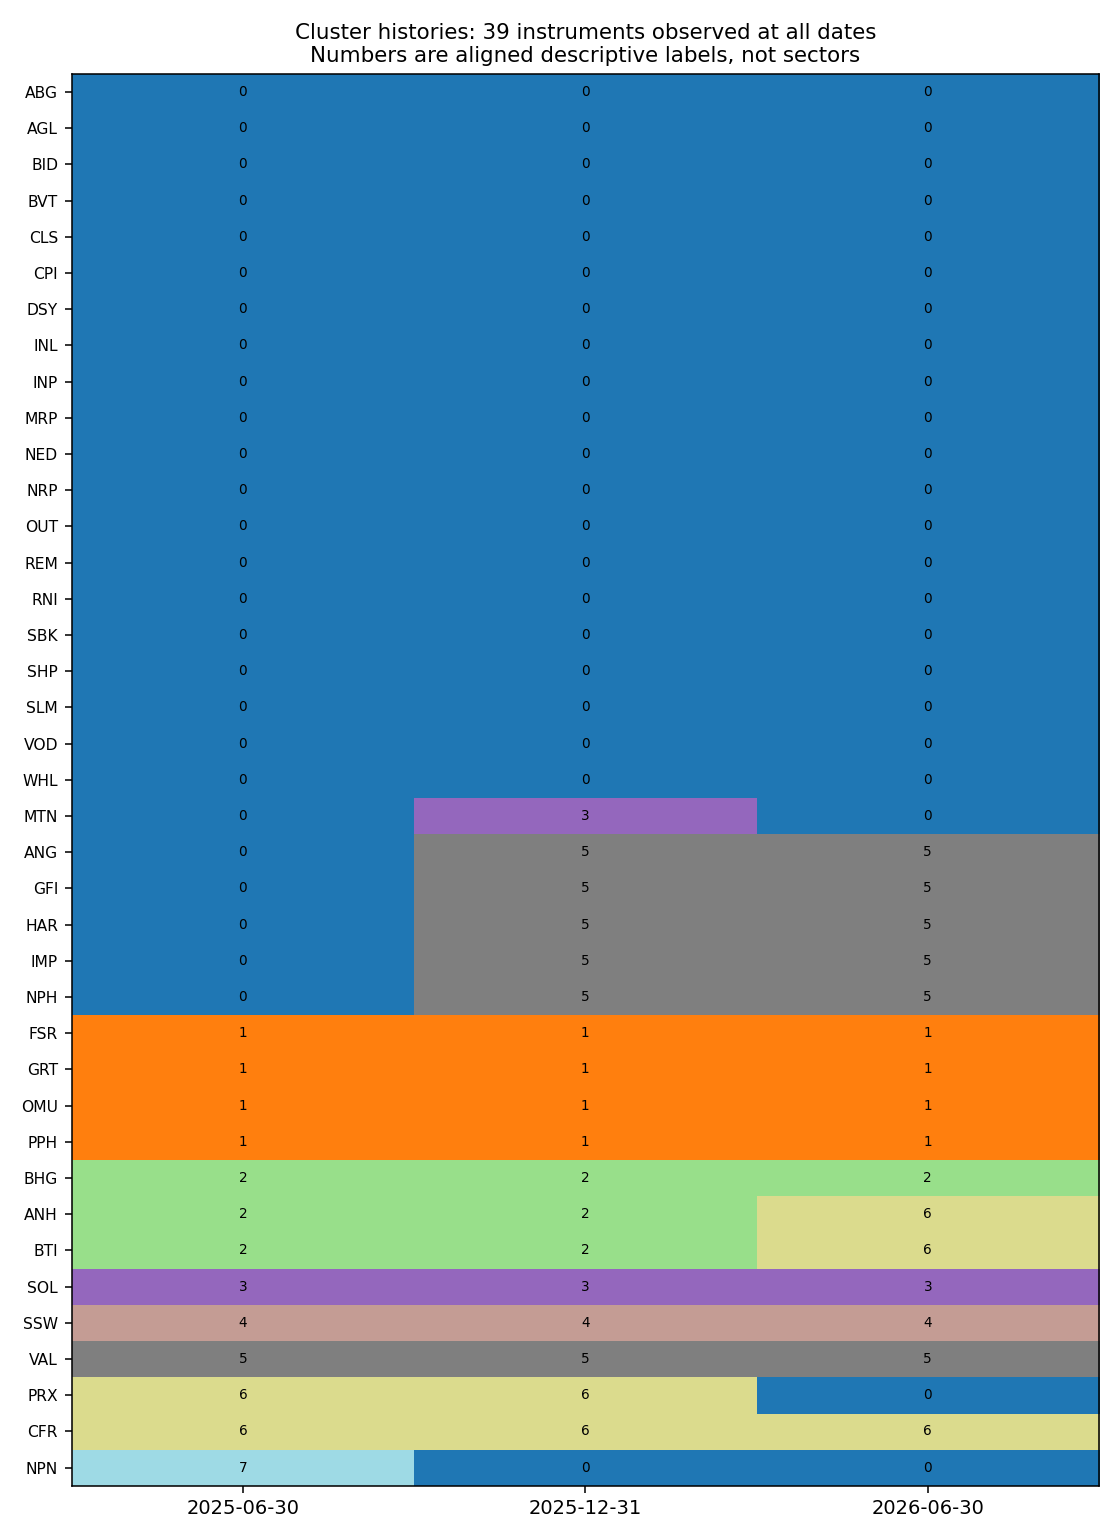

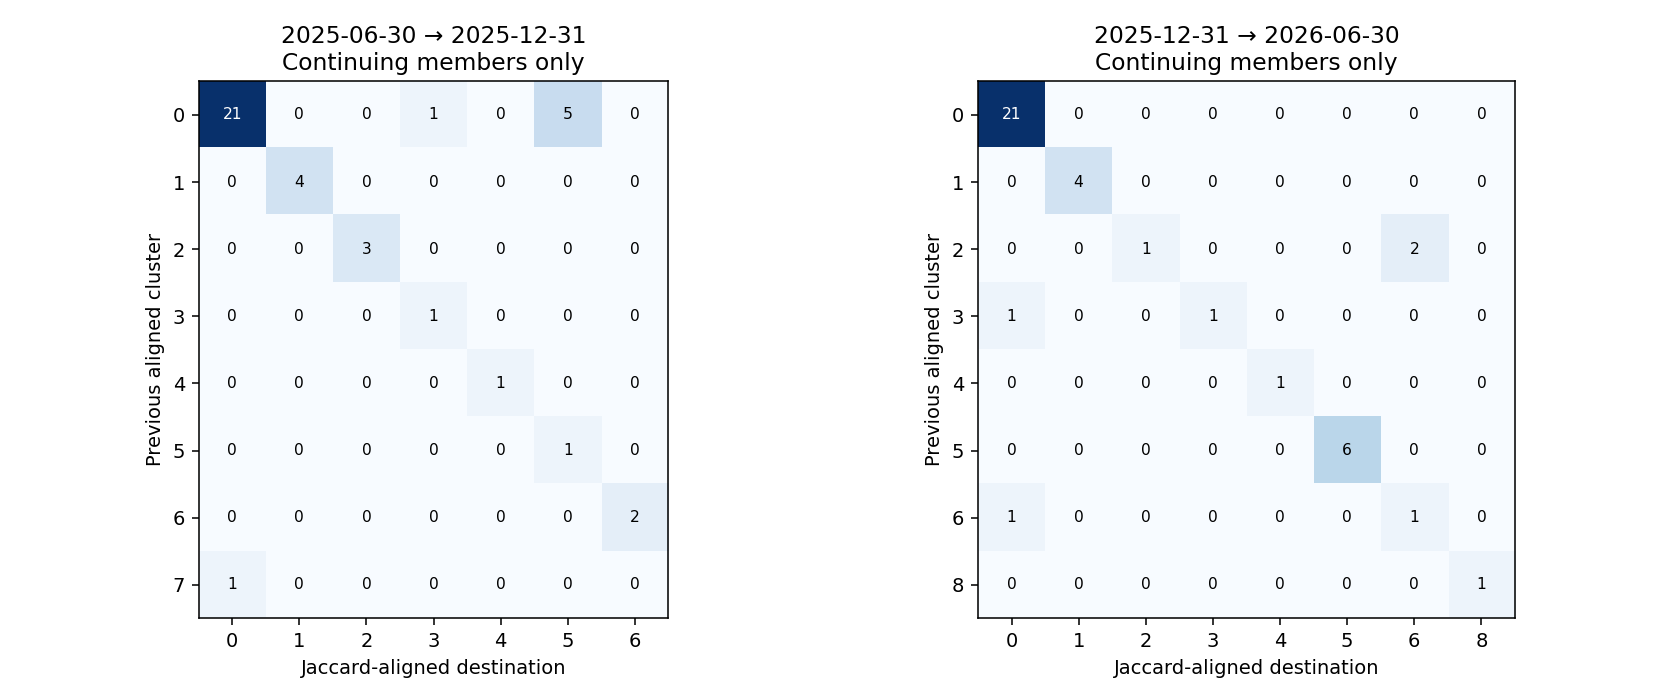

In [10]:
display(study.longitudinal_review())
review = study.table("longitudinal_summary.csv")
PRIMARY_FOLDER = f"models/{PRIMARY}"
if (study.out / PRIMARY_FOLDER / "company_cluster_histories.csv").exists():
    display(study.table(f"{PRIMARY_FOLDER}/stable_instruments.csv"))
    display(study.table(f"{PRIMARY_FOLDER}/shifted_instruments.csv"))
    display(study.table(f"{PRIMARY_FOLDER}/membership_transitions.csv").query("membership_event != 'continuing'"))
    study.show_figure(f"{PRIMARY_FOLDER}/cluster_histories.png")
    study.show_figure(f"{PRIMARY_FOLDER}/jaccard_transition_heatmaps.png")

,decision_date,ticker,company,sector_label,raw_cluster,aligned_cluster,sector_mapped_context,sector_mapping_disagreement,individual_d2,screen_flag,...,distance_surrogate_top_features,imputation_sensitive,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,estimable_seeds,seed_flag_fraction,multi_seed_supported
0,2025-06-30,ABG,ABSA GROUP LTD,Financials,0,0,Financials,False,1.641884,False,...,market_cap_zar; dividend_yield; earnings_yield...,False,Financials,False,contextual comparison,28,False,5,0.0,False
1,2025-06-30,AGL,ANGLO AMERICAN PLC,Basic Materials,0,0,Financials,True,0.268911,False,...,market_cap_zar; dividend_yield; earnings_yield...,True,Financials,True,contextual comparison,28,False,5,0.0,False
2,2025-06-30,ANG,ANGLOGOLD ASHANTI PLC,Basic Materials,0,0,Financials,True,1.370321,False,...,dividend_yield; market_cap_zar; beta_1y,False,Financials,True,contextual comparison,28,False,5,0.0,False
3,2025-06-30,ANH,ANHEUSER-BUSCH INBEV SA/N,Consumer Goods,2,2,Consumer Goods,False,10.944362,True,...,market_cap_zar; shares_outstanding; return_1y,False,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,3,False,5,1.0,True
4,2025-06-30,APN,ASPEN PHARMACARE HLD,Health Care,0,0,Financials,True,0.455271,False,...,market_cap_zar; dividend_yield; shares_outstan...,False,Financials,True,contextual comparison,28,False,5,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,2026-06-30,SOL,SASOL LTD,Basic Materials,4,3,Technology,True,0.642569,False,...,shares_outstanding; beta_1y; revenue_zar_model,False,NaN,NaN,not estimable: singleton,1,True,5,0.0,False
119,2026-06-30,SSW,SIBANYE STILLWATER LTD,Basic Materials,6,4,Telecommunications,True,5.888380,False,...,beta_1y; shares_outstanding; eps_zar_model,False,NaN,NaN,not estimable: singleton,1,True,5,0.0,False
120,2026-06-30,VAL,VALTERRA PLATINUM LTD,Basic Materials,2,5,Basic Materials,False,3.249885,False,...,beta_1y; shares_outstanding; revenue_zar_model,False,Basic Materials,False,contextual comparison,7,False,5,0.0,False
121,2026-06-30,VOD,VODACOM GROUP,Telecommunications,0,0,Financials,True,0.395942,False,...,shares_outstanding; beta_1y; revenue_zar_model,False,Financials,True,contextual comparison,23,False,5,0.0,False


,ticker,2025-06-30,2025-12-31,2026-06-30,screen_history,confirmed_outlier
0,ABG,False,False,False,never flagged,False
1,AGL,False,False,False,never flagged,False
2,ANG,False,False,False,never flagged,False
3,ANH,True,False,False,resolving,False
4,APN,False,NaN,NaN,not eligible: missing observation/screen,False
5,BHG,True,False,False,resolving,False
6,BID,False,False,False,never flagged,False
7,BTI,False,False,False,never flagged,False
8,BVT,False,False,False,never flagged,False
9,CFR,False,False,False,never flagged,False


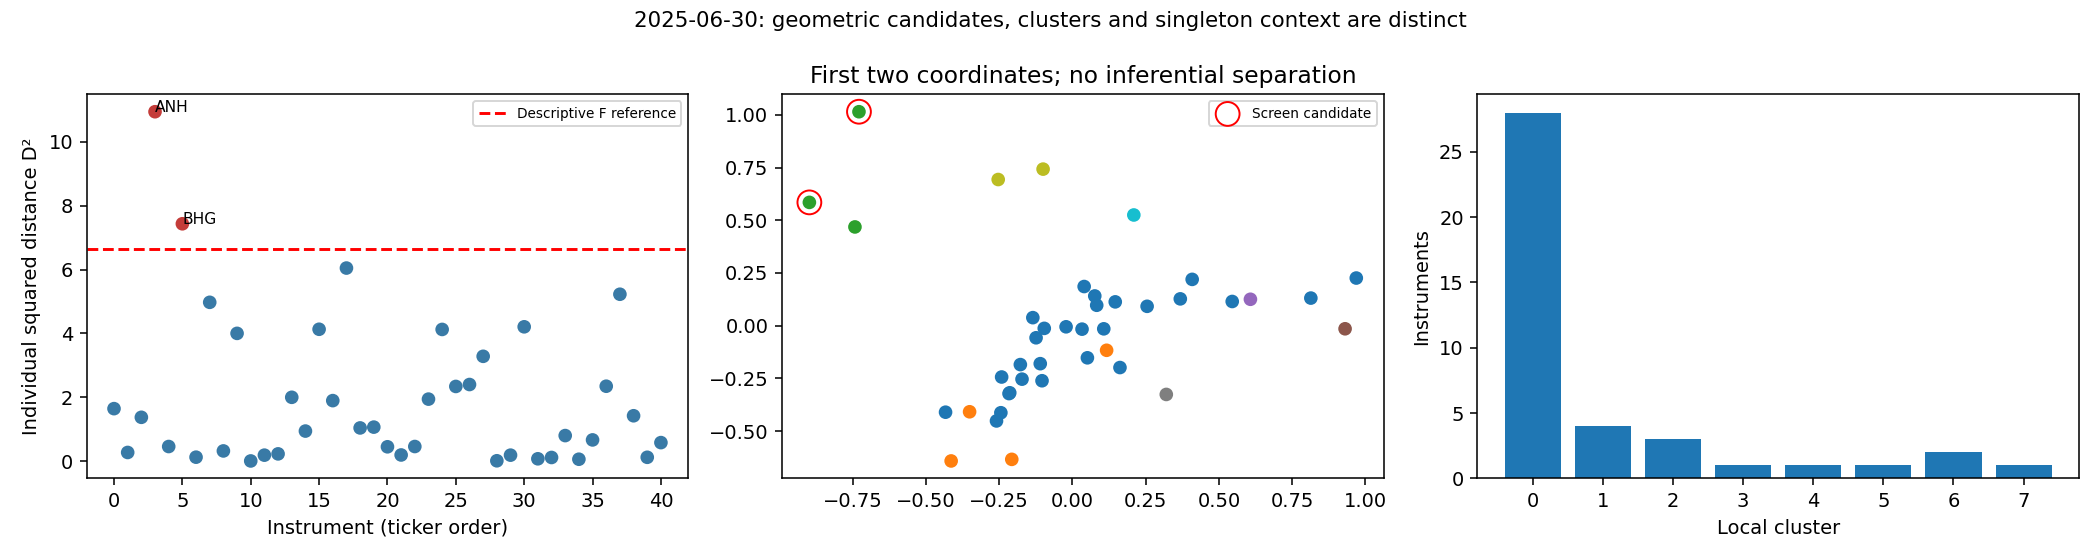

,ticker,cluster,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,decision_date
0,ABG,0,Financials,Financials,False,contextual comparison,28,False,2025-06-30
1,AGL,0,Basic Materials,Financials,True,contextual comparison,28,False,2025-06-30
2,ANG,0,Basic Materials,Financials,True,contextual comparison,28,False,2025-06-30
3,ANH,2,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,3,False,2025-06-30
4,APN,0,Health Care,Financials,True,contextual comparison,28,False,2025-06-30
5,BHG,2,Basic Materials,Consumer Goods,True,contextual comparison,3,False,2025-06-30
6,BID,0,Consumer Services,Financials,True,contextual comparison,28,False,2025-06-30
7,BTI,2,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,3,False,2025-06-30
8,BVT,0,Industrials,Financials,True,contextual comparison,28,False,2025-06-30
9,CFR,6,Consumer Goods,Technology,True,contextual comparison,2,False,2025-06-30


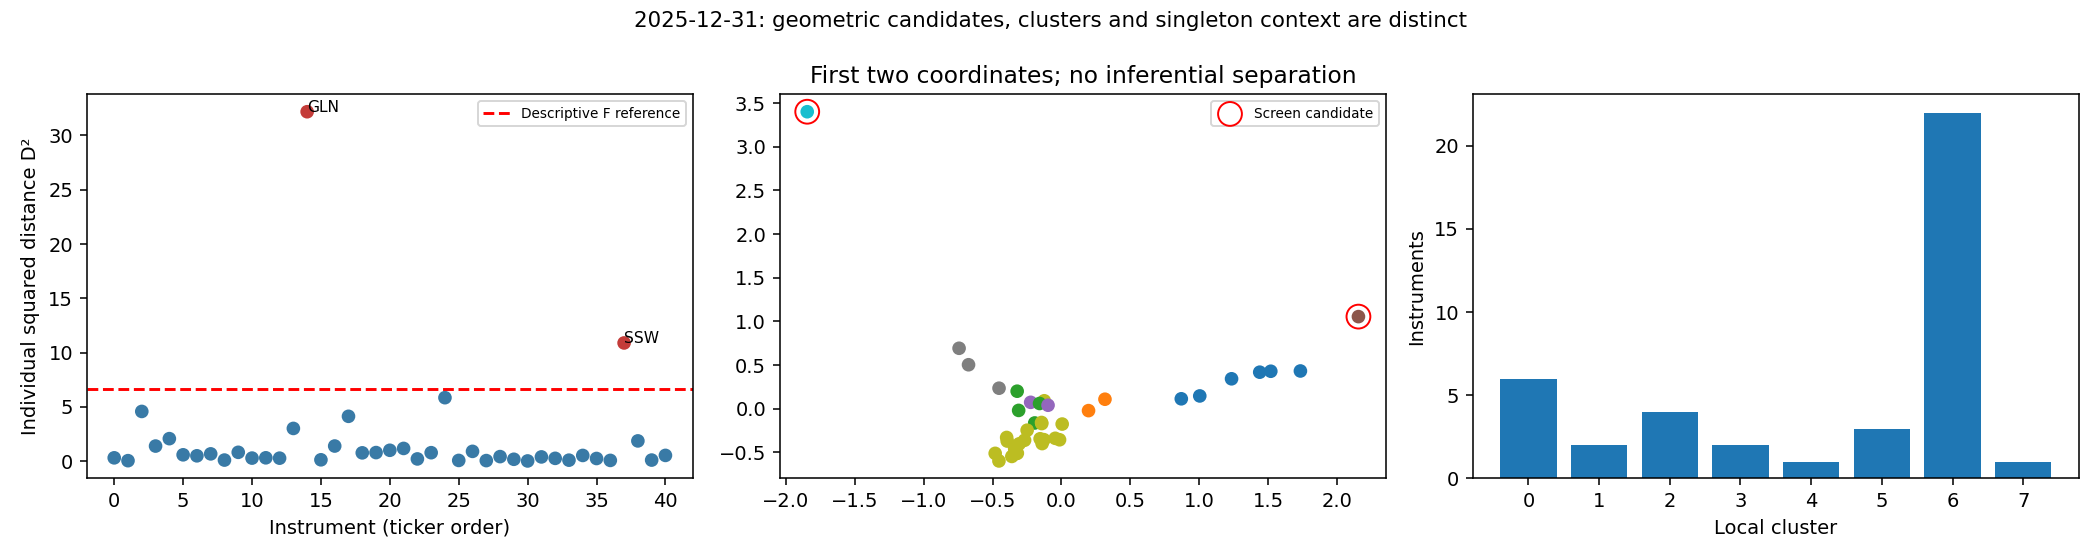

,ticker,cluster,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,decision_date
0,ABG,6,Financials,Financials,False,contextual comparison,22,False,2025-12-31
1,AGL,6,Basic Materials,Financials,True,contextual comparison,22,False,2025-12-31
2,ANG,0,Basic Materials,Basic Materials,False,contextual comparison,6,False,2025-12-31
3,ANH,5,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,3,False,2025-12-31
4,BHG,5,Basic Materials,Consumer Goods,True,contextual comparison,3,False,2025-12-31
5,BID,6,Consumer Services,Financials,True,contextual comparison,22,False,2025-12-31
6,BTI,5,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,3,False,2025-12-31
7,BVT,6,Industrials,Financials,True,contextual comparison,22,False,2025-12-31
8,CFR,3,Consumer Goods,Technology,True,contextual comparison,2,False,2025-12-31
9,CLS,6,Consumer Services,Financials,True,contextual comparison,22,False,2025-12-31


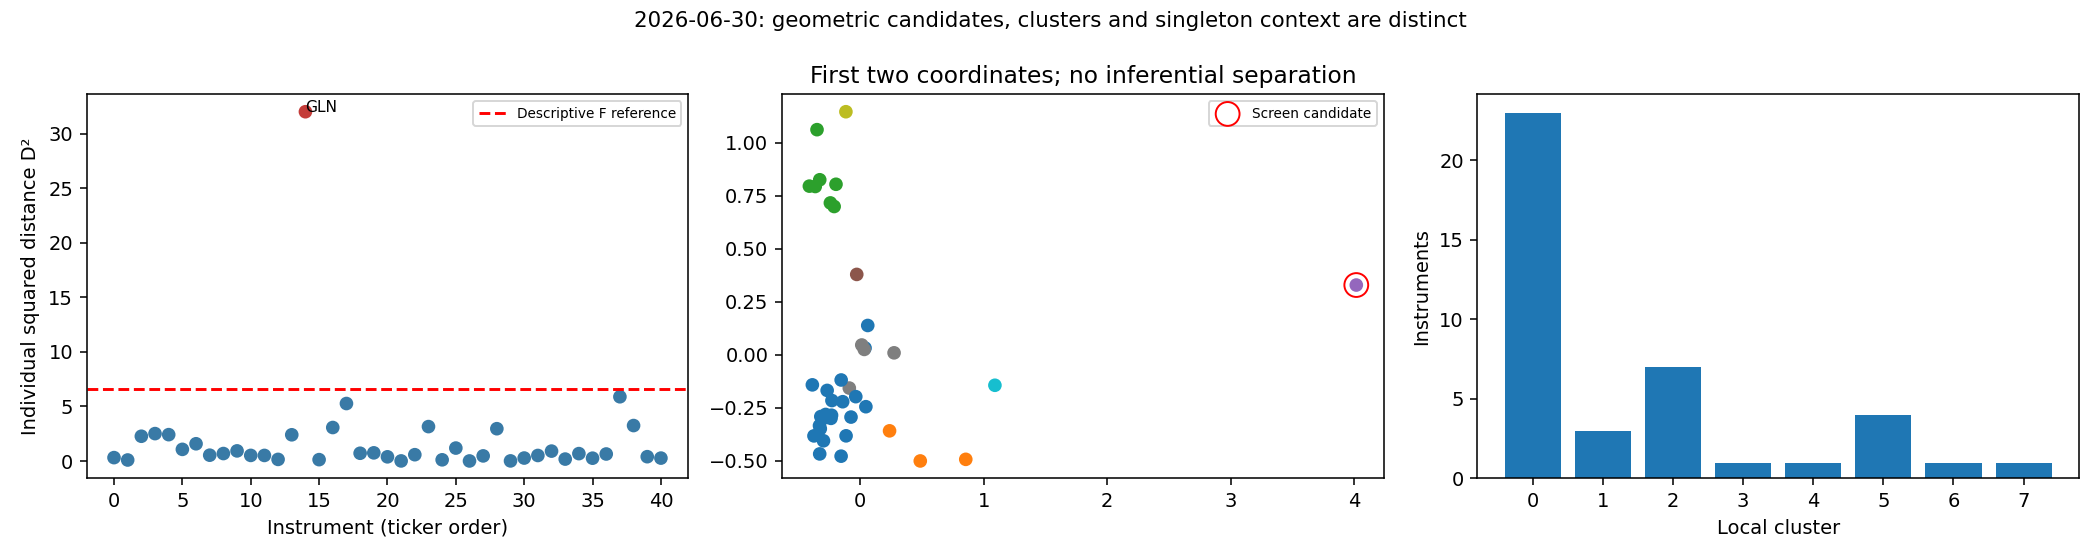

,ticker,cluster,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,decision_date
0,ABG,0,Financials,Financials,False,contextual comparison,23,False,2026-06-30
1,AGL,0,Basic Materials,Financials,True,contextual comparison,23,False,2026-06-30
2,ANG,2,Basic Materials,Basic Materials,False,contextual comparison,7,False,2026-06-30
3,ANH,1,Consumer Goods,Consumer Goods,False,contextual comparison,3,False,2026-06-30
4,BHG,7,Basic Materials,NaN,NaN,not estimable: singleton,1,True,2026-06-30
5,BID,0,Consumer Services,Financials,True,contextual comparison,23,False,2026-06-30
6,BTI,1,Consumer Goods,Consumer Goods,False,contextual comparison,3,False,2026-06-30
7,BVT,0,Industrials,Financials,True,contextual comparison,23,False,2026-06-30
8,CFR,1,Consumer Goods,Consumer Goods,False,contextual comparison,3,False,2026-06-30
9,CLS,0,Consumer Services,Financials,True,contextual comparison,23,False,2026-06-30


In [11]:
if (study.out / PRIMARY_FOLDER / "company_case_summary.csv").exists():
    cases = study.table(f"{PRIMARY_FOLDER}/company_case_summary.csv")
    display(cases)
    display(study.table(f"{PRIMARY_FOLDER}/outlier_screen_histories.csv"))
    for date in study.config["dates"]:
        study.show_figure(f"{PRIMARY_FOLDER}/{date}/outlier_screen.png")
        display(study.table(f"{PRIMARY_FOLDER}/{date}/sector_context.csv"))

## 6. Explain attributes, with the correct SHAP target

Three distinct explanations are saved:

1. Each date's classifier surrogate: associations with cluster membership, with in-sample/OOF fidelity and raw-margin additivity checks.
2. A separate regression surrogate of the geometric distance: associations with the screening score itself, with train/OOF R? and MAE. Cluster SHAP alone does not explain the Hotelling distance.
3. A **frozen 2025 classifier** evaluated at each continuing firm's 2025 and later feature vector. Destination-versus-source class SHAP contrasts are differenced within that same model. They sum to the margin-contrast change. This is an attribute-change description, not causal proof of why independently refitted clusters shifted. Unmatched destinations without a 2025 class are explicitly not estimable.

The instrument-level case report includes top SHAP attributes, actual feature changes, deviations from population medians, imputation flags and sector context. Stable-class zero contrasts do not imply unchanged finances. The case plots and all ten feature contributions are saved, rather than reporting only selected favourable examples.

# Instrument case review

Screens are candidates, not confirmed outliers. Sector divergence and singletons are separate contextual flags. SHAP describes surrogates, not causal explanations. Review fidelity and imputation flags before interpreting attributes.

## Stable and shifted memberships

Stable at every observed study date: ABG, AGL, BHG, BID, BVT, CFR, CLS, CPI, DSY, FSR, GRT, INL, INP, MRP, NED, NRP, OMU, OUT, PPH, REM, RNI, SBK, SHP, SLM, SOL, SSW, VAL, VOD, WHL.

Changed at least once among all-three-date members: ANG, ANH, BTI, GFI, HAR, IMP, MTN, NPH, NPN, PRX.

Membership gaps: APN, GLN, MNP, PAN. Entries/exits receive no ordinary shift or resolving flag.

## Screen histories

- ANH: resolving.
- APN: not eligible: missing observation/screen.
- BHG: resolving.
- GLN: not eligible: missing observation/screen.
- MNP: not eligible: missing observation/screen.
- PAN: not eligible: missing observation/screen.
- SSW: transient.

## Per-date candidates and sector divergence

- 2025-06-30 **AGL**: D²=0.269; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=True. Cluster-surrogate features: revenue_zar_model; eps_zar_model; shares_outstanding. Distance-surrogate features: market_cap_zar; dividend_yield; earnings_yield_model_clipped.
- 2025-06-30 **ANG**: D²=1.370; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; eps_zar_model; shares_outstanding. Distance-surrogate features: dividend_yield; market_cap_zar; beta_1y.
- 2025-06-30 **ANH**: D²=10.944; screen=True; seed support=100%; sector divergence=None; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; market_cap_zar; average_daily_volume_1y_model. Distance-surrogate features: market_cap_zar; shares_outstanding; return_1y.
- 2025-06-30 **APN**: D²=0.455; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: market_cap_zar; dividend_yield; shares_outstanding.
- 2025-06-30 **BHG**: D²=7.434; screen=True; seed support=100%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; market_cap_zar; average_daily_volume_1y_model. Distance-surrogate features: market_cap_zar; shares_outstanding; return_1y.
- 2025-06-30 **BID**: D²=0.121; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; annualised_volatility_1y. Distance-surrogate features: market_cap_zar; shares_outstanding; dividend_yield.
- 2025-06-30 **BVT**: D²=0.317; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; annualised_volatility_1y. Distance-surrogate features: market_cap_zar; dividend_yield; beta_1y.
- 2025-06-30 **CFR**: D²=4.000; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: market_cap_zar; eps_zar_model; beta_1y. Distance-surrogate features: market_cap_zar; return_1y; shares_outstanding.
- 2025-06-30 **CLS**: D²=0.003; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: shares_outstanding; market_cap_zar; beta_1y.
- 2025-06-30 **GFI**: D²=0.939; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: dividend_yield; market_cap_zar; beta_1y.
- 2025-06-30 **HAR**: D²=1.893; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: market_cap_zar; annualised_volatility_1y; dividend_yield.
- 2025-06-30 **IMP**: D²=6.046; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; annualised_volatility_1y; shares_outstanding. Distance-surrogate features: beta_1y; dividend_yield; annualised_volatility_1y.
- 2025-06-30 **MNP**: D²=0.447; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; annualised_volatility_1y. Distance-surrogate features: market_cap_zar; dividend_yield; shares_outstanding.
- 2025-06-30 **MRP**: D²=0.190; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: market_cap_zar; dividend_yield; shares_outstanding.
- 2025-06-30 **MTN**: D²=0.455; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: dividend_yield; market_cap_zar; beta_1y.
- 2025-06-30 **NPH**: D²=4.123; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; annualised_volatility_1y; shares_outstanding. Distance-surrogate features: dividend_yield; beta_1y; annualised_volatility_1y.
- 2025-06-30 **NPN**: D²=2.337; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: shares_outstanding; earnings_yield_model_clipped; dividend_yield. Distance-surrogate features: dividend_yield; market_cap_zar; shares_outstanding.
- 2025-06-30 **PPH**: D²=0.185; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; average_daily_volume_1y_model; revenue_zar_model. Distance-surrogate features: shares_outstanding; dividend_yield; market_cap_zar.
- 2025-06-30 **PRX**: D²=4.206; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: market_cap_zar; eps_zar_model; beta_1y. Distance-surrogate features: market_cap_zar; dividend_yield; return_1y.
- 2025-06-30 **SHP**: D²=0.057; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; annualised_volatility_1y. Distance-surrogate features: market_cap_zar; dividend_yield; shares_outstanding.
- 2025-06-30 **SOL**: D²=2.344; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: market_cap_zar; return_1y; revenue_zar_model. Distance-surrogate features: dividend_yield; market_cap_zar; annualised_volatility_1y.
- 2025-06-30 **SSW**: D²=5.226; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; beta_1y. Distance-surrogate features: beta_1y; dividend_yield; shares_outstanding.
- 2025-06-30 **VAL**: D²=1.419; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: dividend_yield; shares_outstanding; beta_1y. Distance-surrogate features: beta_1y; shares_outstanding; market_cap_zar.
- 2025-06-30 **VOD**: D²=0.118; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; eps_zar_model; annualised_volatility_1y. Distance-surrogate features: dividend_yield; market_cap_zar; shares_outstanding.
- 2025-06-30 **WHL**: D²=0.578; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; eps_zar_model. Distance-surrogate features: market_cap_zar; dividend_yield; beta_1y.
- 2025-12-31 **AGL**: D²=0.047; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=True. Cluster-surrogate features: shares_outstanding; revenue_zar_model; return_1y. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **BHG**: D²=2.075; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: revenue_zar_model; market_cap_zar; annualised_volatility_1y. Distance-surrogate features: revenue_zar_model; return_1y; shares_outstanding.
- 2025-12-31 **BID**: D²=0.586; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **BVT**: D²=0.673; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **CFR**: D²=0.102; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: market_cap_zar; eps_zar_model; dividend_yield. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **CLS**: D²=0.816; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **GLN**: D²=32.187; screen=True; seed support=100%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: revenue_zar_model; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; revenue_zar_model; return_1y.
- 2025-12-31 **MNP**: D²=1.003; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; market_cap_zar. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **MRP**: D²=1.174; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; market_cap_zar. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **MTN**: D²=0.207; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; revenue_zar_model; average_daily_volume_1y_model. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **NPN**: D²=0.069; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; average_daily_volume_1y_model. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **PPH**: D²=0.174; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: average_daily_volume_1y_model; shares_outstanding; annualised_volatility_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **PRX**: D²=0.021; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: market_cap_zar; eps_zar_model; dividend_yield. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **SHP**: D²=0.528; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2025-12-31 **SOL**: D²=0.071; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; revenue_zar_model; average_daily_volume_1y_model. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **SSW**: D²=10.890; screen=True; seed support=100%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: shares_outstanding; dividend_yield; return_1y. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **VOD**: D²=0.101; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; return_1y; shares_outstanding. Distance-surrogate features: return_1y; shares_outstanding; revenue_zar_model.
- 2025-12-31 **WHL**: D²=0.532; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; return_1y; revenue_zar_model.
- 2026-06-30 **AGL**: D²=0.092; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; annualised_volatility_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **BHG**: D²=2.416; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: average_daily_volume_1y_model; beta_1y; shares_outstanding. Distance-surrogate features: revenue_zar_model; shares_outstanding; beta_1y.
- 2026-06-30 **BID**: D²=1.067; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **BVT**: D²=0.532; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **CLS**: D²=0.927; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **GLN**: D²=32.013; screen=True; seed support=100%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: earnings_yield_model_clipped; average_daily_volume_1y_model; return_1y. Distance-surrogate features: shares_outstanding; revenue_zar_model; return_1y.
- 2026-06-30 **MRP**: D²=0.384; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; revenue_zar_model. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **MTN**: D²=0.008; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; average_daily_volume_1y_model; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **NPN**: D²=0.110; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: shares_outstanding; return_1y; revenue_zar_model. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **PPH**: D²=0.010; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: average_daily_volume_1y_model; shares_outstanding; earnings_yield_model_clipped. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **PRX**: D²=0.271; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: return_1y; annualised_volatility_1y; revenue_zar_model. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **SHP**: D²=0.677; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **SOL**: D²=0.643; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: beta_1y; annualised_volatility_1y; dividend_yield. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **SSW**: D²=5.888; screen=False; seed support=0%; sector divergence=None; singleton=True; imputed=False. Cluster-surrogate features: beta_1y; return_1y; average_daily_volume_1y_model. Distance-surrogate features: beta_1y; shares_outstanding; eps_zar_model.
- 2026-06-30 **VOD**: D²=0.396; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.
- 2026-06-30 **WHL**: D²=0.266; screen=False; seed support=0%; sector divergence=True; singleton=False; imputed=False. Cluster-surrogate features: annualised_volatility_1y; shares_outstanding; return_1y. Distance-surrogate features: shares_outstanding; beta_1y; revenue_zar_model.

## 2025-to-later attribute shifts in the frozen 2025 surrogate

The same 2025 model is evaluated at both feature vectors. We subtract destination-versus-source class SHAP contrasts. Their sum equals the change in the same-model raw-margin contrast. This does not prove why independently refitted clusters changed; changing peers and the representation also matter. Stable firms have identical source/destination labels and a zero contrast by construction; inspect their raw feature changes rather than interpreting zero as no financial change.

- **ANG**, 2025-06-30 → 2025-12-31: beta_1y: value 1.075 → 1.578, contrast-SHAP change +0.563; shares_outstanding: value 5.035e+08 → 5.049e+08, contrast-SHAP change +0.044; earnings_yield_model_clipped: value 0.05173 → 0.0269, contrast-SHAP change -0.040.
- **ANG**, 2025-06-30 → 2026-06-30: revenue_zar_model: value 1.03e+11 → 1.62e+11, contrast-SHAP change +1.656; beta_1y: value 1.075 → 2.243, contrast-SHAP change +0.607; eps_zar_model: value 41.43 → 84.81, contrast-SHAP change +0.533.
- **ANH**, 2025-06-30 → 2026-06-30: return_1y: value 0.1462 → 0.1228, contrast-SHAP change +0.000; average_daily_volume_1y_model: value 4.705e+05 → 3.93e+05, contrast-SHAP change +0.000; market_cap_zar: value 2.407e+12 → 2.669e+12, contrast-SHAP change +0.000.
- **BTI**, 2025-06-30 → 2026-06-30: revenue_zar_model: value 6.302e+11 → 5.544e+11, contrast-SHAP change +3.479; market_cap_zar: value 1.852e+12 → 2.221e+12, contrast-SHAP change +1.978; eps_zar_model: value 33.13 → 75.57, contrast-SHAP change +0.169.
- **GFI**, 2025-06-30 → 2025-12-31: beta_1y: value 1.148 → 1.61, contrast-SHAP change +0.556; earnings_yield_model_clipped: value 0.05902 → 0.03147, contrast-SHAP change +0.030; revenue_zar_model: value 9.25e+10 → 8.608e+10, contrast-SHAP change -0.029.
- **GFI**, 2025-06-30 → 2026-06-30: revenue_zar_model: value 9.25e+10 → 1.433e+11, contrast-SHAP change +1.527; eps_zar_model: value 24.54 → 64.51, contrast-SHAP change +1.270; annualised_volatility_1y: value 0.4664 → 0.5584, contrast-SHAP change +0.990.
- **HAR**, 2025-06-30 → 2025-12-31: annualised_volatility_1y: value 0.5185 → 0.5565, contrast-SHAP change +0.714; beta_1y: value 1.296 → 1.711, contrast-SHAP change +0.235; market_cap_zar: value 1.523e+11 → 2.097e+11, contrast-SHAP change +0.026.
- **HAR**, 2025-06-30 → 2026-06-30: annualised_volatility_1y: value 0.5185 → 0.6137, contrast-SHAP change +0.714; beta_1y: value 1.296 → 2.384, contrast-SHAP change +0.235; revenue_zar_model: value 6.138e+10 → 7.39e+10, contrast-SHAP change +0.158.
- **IMP**, 2025-06-30 → 2025-12-31: dividend_yield: value 0 → 0.006298, contrast-SHAP change -0.125; eps_zar_model: value -19.24 → 0.84, contrast-SHAP change +0.006; shares_outstanding: value 8.968e+08 → 8.97e+08, contrast-SHAP change -0.006.
- **IMP**, 2025-06-30 → 2026-06-30: dividend_yield: value 0 → 0.03343, contrast-SHAP change -0.265; revenue_zar_model: value 8.64e+10 → 8.546e+10, contrast-SHAP change +0.140; eps_zar_model: value -19.24 → 0.84, contrast-SHAP change +0.006.
- **MTN**, 2025-06-30 → 2025-12-31: return_1y: value 0.6581 → 0.8426, contrast-SHAP change +0.000; average_daily_volume_1y_model: value 5.208e+06 → 5.746e+06, contrast-SHAP change +0.000; market_cap_zar: value 2.544e+11 → 3.062e+11, contrast-SHAP change +0.000.
- **NPH**, 2025-06-30 → 2025-12-31: annualised_volatility_1y: value 0.5593 → 0.5503, contrast-SHAP change -0.714; market_cap_zar: value 7.474e+10 → 1.327e+11, contrast-SHAP change -0.082; eps_zar_model: value 4.61 → 3.774, contrast-SHAP change +0.053.
- **NPH**, 2025-06-30 → 2026-06-30: revenue_zar_model: value 3.077e+10 → 3.29e+10, contrast-SHAP change +0.160; dividend_yield: value 0.004434 → 0.03815, contrast-SHAP change -0.140; eps_zar_model: value 4.61 → 3.774, contrast-SHAP change +0.053.
- **NPN**, 2025-06-30 → 2025-12-31: market_cap_zar: value 8.954e+11 → 8.186e+11, contrast-SHAP change +1.099; shares_outstanding: value 1.623e+08 → 7.411e+08, contrast-SHAP change +1.032; earnings_yield_model_clipped: value 0.09598 → 0.0892, contrast-SHAP change +0.536.
- **NPN**, 2025-06-30 → 2026-06-30: market_cap_zar: value 8.954e+11 → 6.262e+11, contrast-SHAP change +1.099; shares_outstanding: value 1.623e+08 → 7.63e+08, contrast-SHAP change +1.032; dividend_yield: value 0.002185 → 0.00619, contrast-SHAP change +0.460.
- **PRX**, 2025-06-30 → 2026-06-30: market_cap_zar: value 2.261e+12 → 1.512e+12, contrast-SHAP change +2.147; shares_outstanding: value 2.28e+09 → 2.138e+09, contrast-SHAP change +1.773; eps_zar_model: value 90.87 → 85.63, contrast-SHAP change +0.879.


,ticker,after,actual_aligned_cluster_changed,source_cluster,destination_cluster,margin_contrast_change,attribution_sum,status
0,ABG,2025-12-31,False,0,0,0.000000,0.000000,estimated in frozen 2025 surrogate
1,AGL,2025-12-31,False,0,0,0.000000,0.000000,estimated in frozen 2025 surrogate
2,ANG,2025-12-31,True,0,5,0.549491,0.549491,estimated in frozen 2025 surrogate
3,ANH,2025-12-31,False,2,2,0.000000,0.000000,estimated in frozen 2025 surrogate
4,BHG,2025-12-31,False,2,2,0.000000,0.000000,estimated in frozen 2025 surrogate
...,...,...,...,...,...,...,...,...
74,SOL,2026-06-30,False,3,3,0.000000,0.000000,estimated in frozen 2025 surrogate
75,SSW,2026-06-30,False,4,4,0.000000,0.000000,estimated in frozen 2025 surrogate
76,VAL,2026-06-30,False,5,5,0.000000,0.000000,estimated in frozen 2025 surrogate
77,VOD,2026-06-30,False,0,0,0.000000,0.000000,estimated in frozen 2025 surrogate


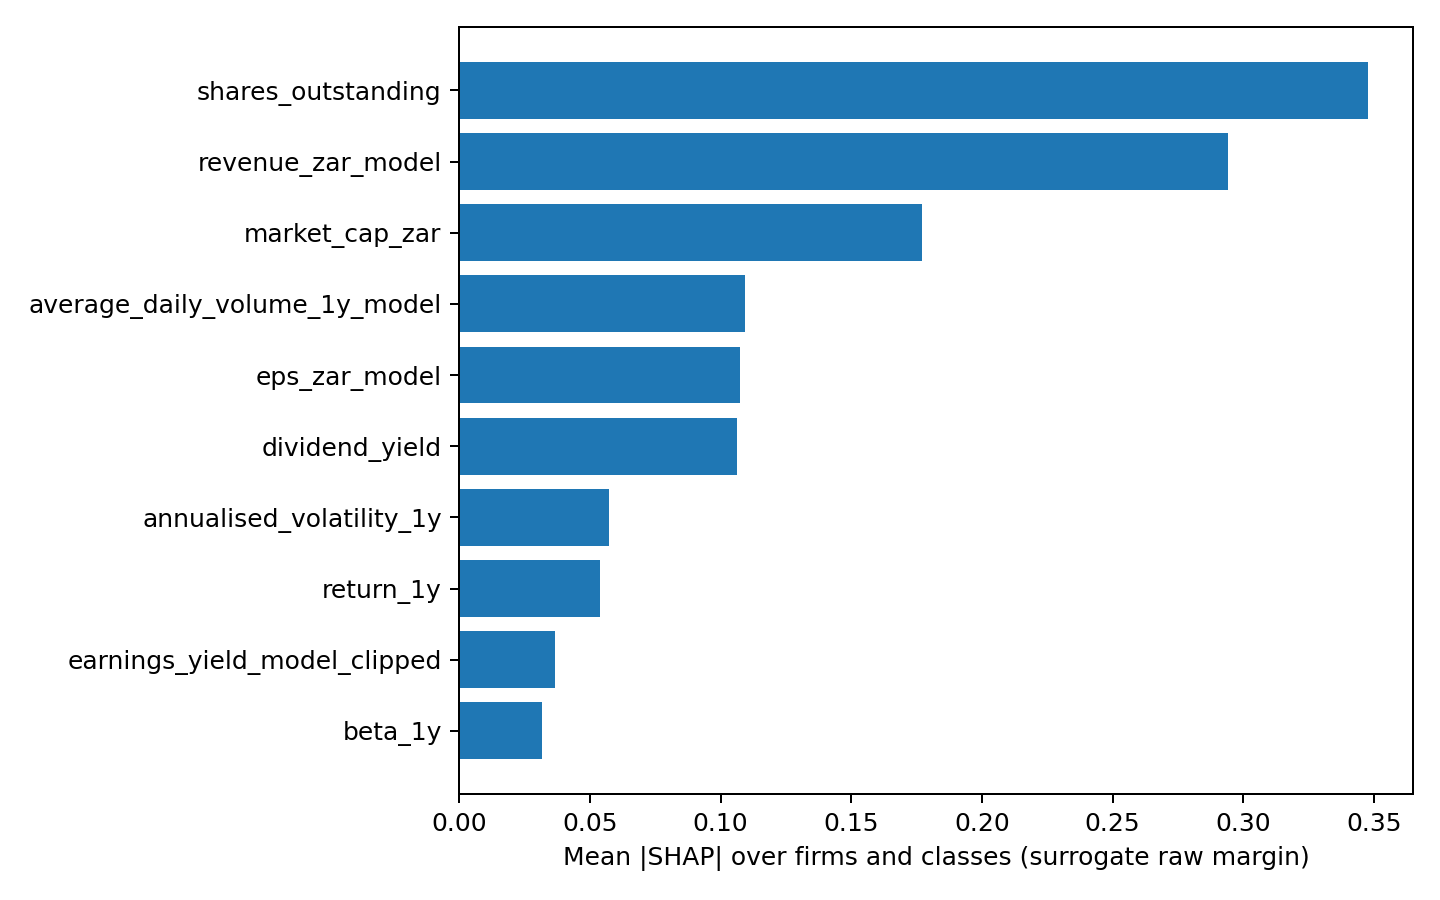

```json
{
  "in_sample_r2": 0.9817166811382667,
  "oof_r2": 0.4605621926087259,
  "oof_mae": 1.1870557495291882,
  "interpretation": "Associations with full-snapshot learned-coordinate screen; OOF fidelity does not validate outlier calibration"
}

```

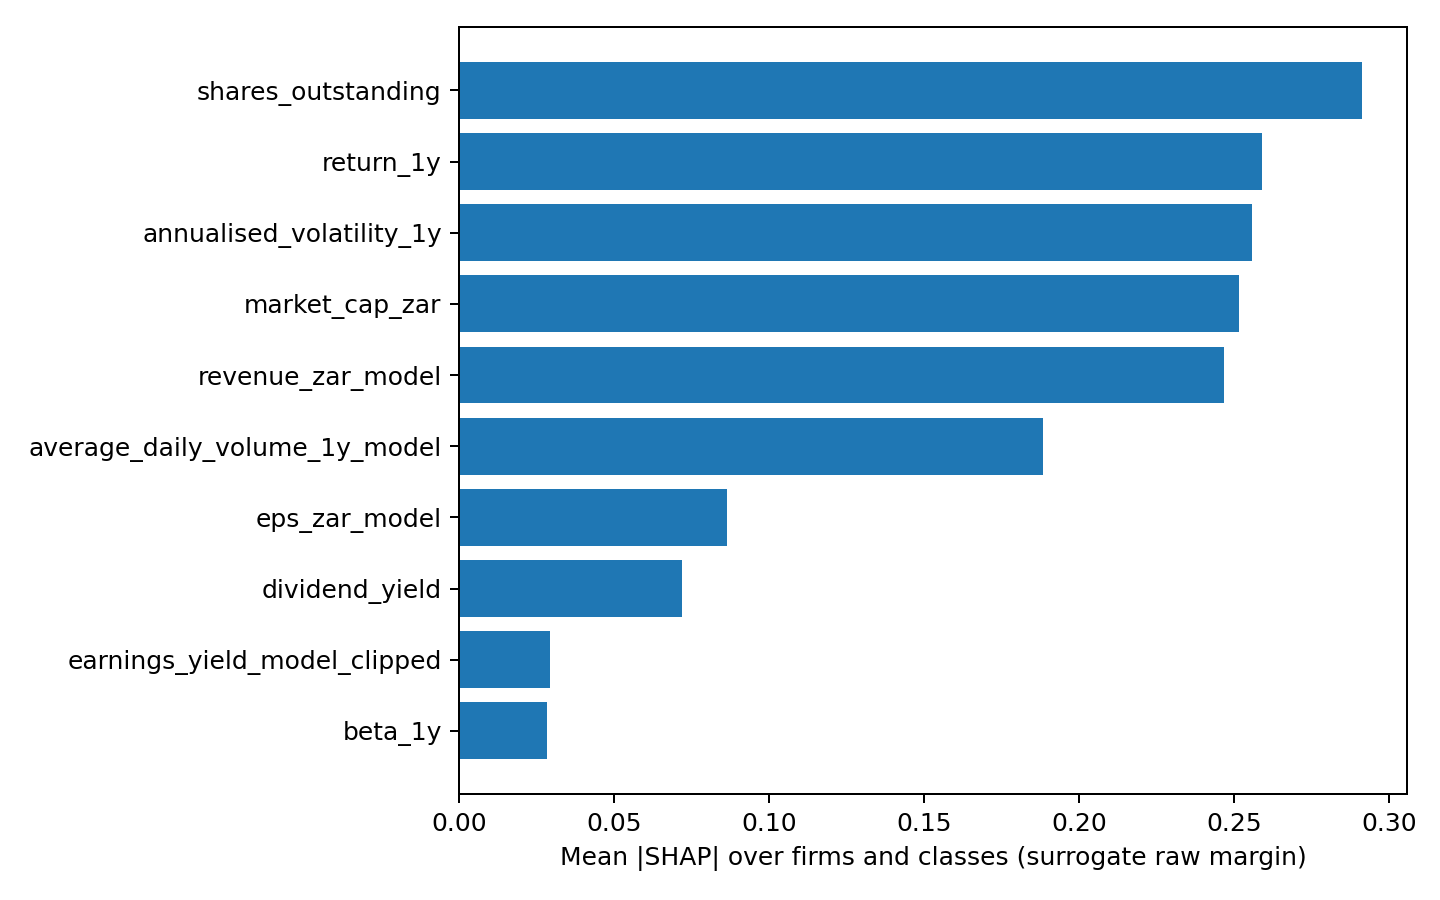

```json
{
  "in_sample_r2": 0.998066512657198,
  "oof_r2": 0.08797014310944617,
  "oof_mae": 1.2603570541559959,
  "interpretation": "Associations with full-snapshot learned-coordinate screen; OOF fidelity does not validate outlier calibration"
}

```

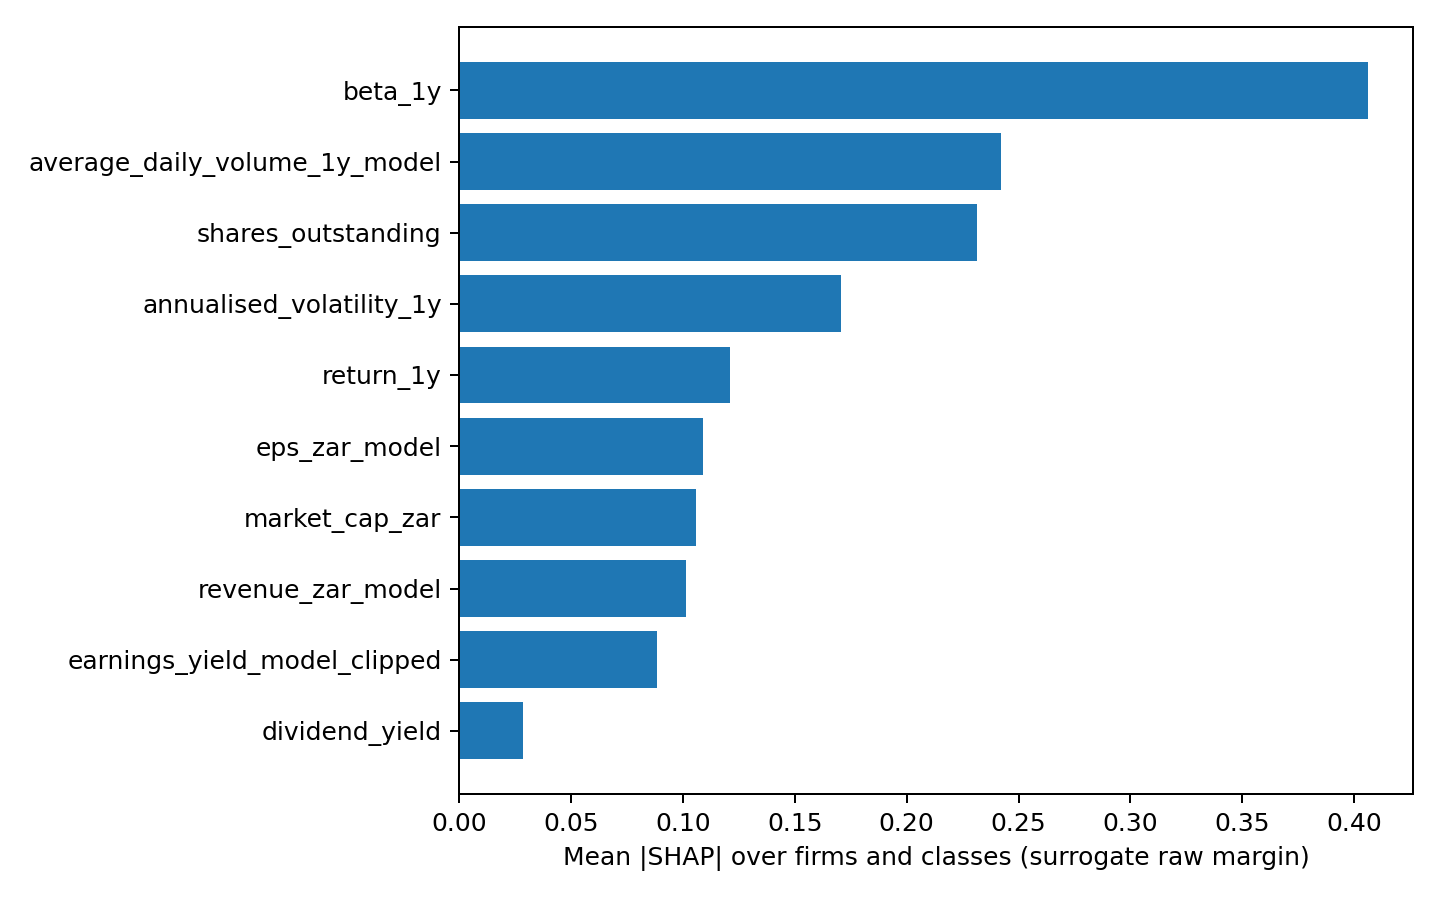

```json
{
  "in_sample_r2": 0.9982353117273166,
  "oof_r2": -0.01900001717911204,
  "oof_mae": 1.2982756382027507,
  "interpretation": "Associations with full-snapshot learned-coordinate screen; OOF fidelity does not validate outlier calibration"
}

```

In [12]:
if (study.out / PRIMARY_FOLDER / "case_review.md").exists():
    display(Markdown((study.out / PRIMARY_FOLDER / "case_review.md").read_text(encoding="utf-8")))
    display(study.table(f"{PRIMARY_FOLDER}/frozen_2025_shift_checks.csv"))
    for date in study.config["dates"]:
        study.show_figure(f"{PRIMARY_FOLDER}/{date}/shap_global.png")
        display(Markdown("```json\n" + (study.out / PRIMARY_FOLDER / date / "screen_surrogate_fidelity.json").read_text() + "\n```"))

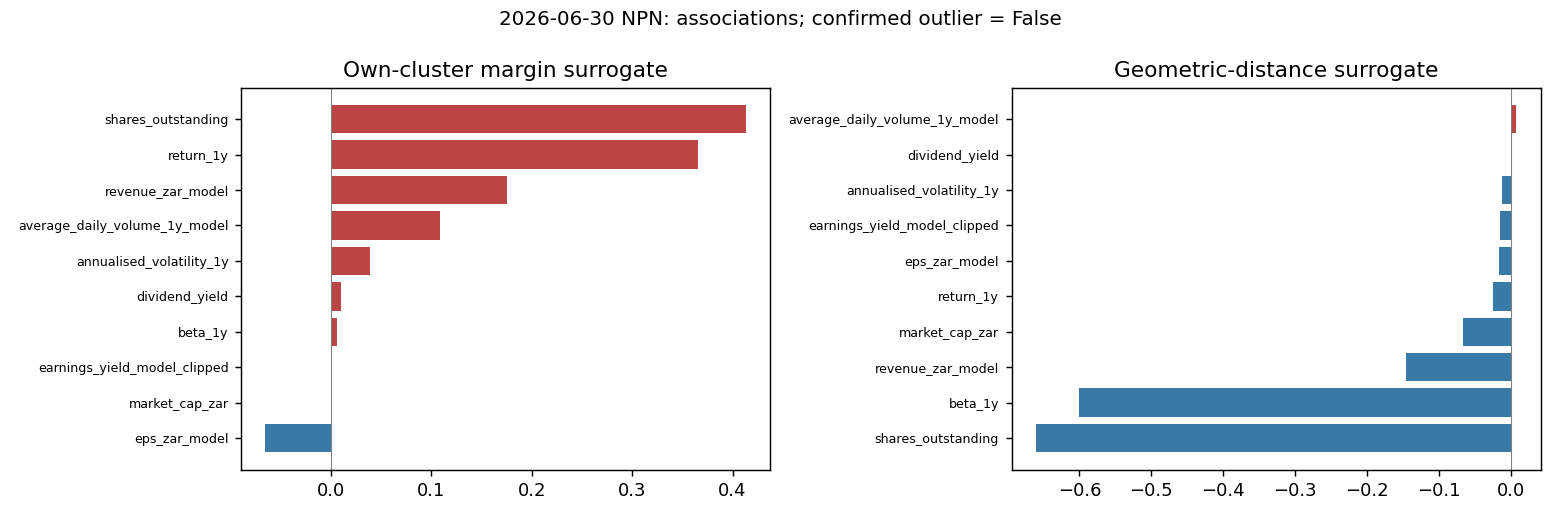

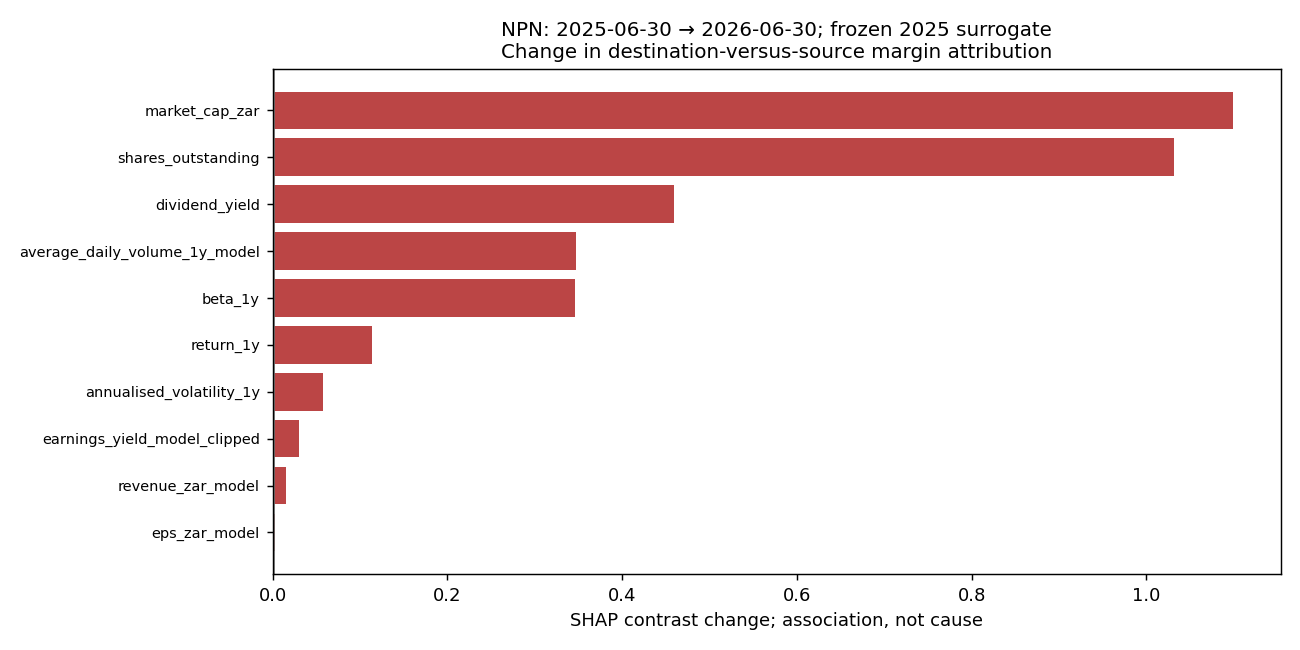

,decision_date,ticker,feature,raw_model_value,scaled_value,deviation_from_snapshot_median,cluster_shap,distance_surrogate_shap,sector_reference_cluster,own_vs_sector_reference_shap
1060,2026-06-30,NPN,return_1y,-2.560621e-01,0.187112,-0.296999,0.365737,-0.024805,0.0,0.0
1061,2026-06-30,NPN,average_daily_volume_1y_model,1.502524e+06,0.076457,-0.007257,0.108448,0.007265,0.0,0.0
1062,2026-06-30,NPN,market_cap_zar,6.261592e+11,0.245873,0.198977,0.000000,-0.067068,0.0,0.0
1063,2026-06-30,NPN,beta_1y,8.390985e-01,0.384208,0.109520,0.006563,-0.600558,0.0,0.0
1064,2026-06-30,NPN,shares_outstanding,7.630318e+08,0.118135,-0.022266,0.413561,-0.660670,0.0,0.0
1065,2026-06-30,NPN,revenue_zar_model,1.776048e+11,0.155666,0.059048,0.175644,-0.146500,0.0,0.0
1066,2026-06-30,NPN,eps_zar_model,1.000337e+02,0.283608,0.143636,-0.064989,-0.016508,0.0,0.0
1067,2026-06-30,NPN,annualised_volatility_1y,3.254063e-01,0.365456,0.179954,0.038620,-0.012930,0.0,0.0
1068,2026-06-30,NPN,dividend_yield,6.190441e-03,0.068186,-0.352029,0.009782,0.000000,0.0,0.0
1069,2026-06-30,NPN,earnings_yield_model_clipped,1.219001e-01,0.966723,0.082912,0.000000,-0.016214,0.0,0.0


In [13]:
# Change TICKER and VIEW_DATE to inspect an individual case. No refitting occurs.
TICKER = "NPN"
VIEW_DATE = "2026-06-30"
for name in [f"{VIEW_DATE}_{TICKER}.png", f"shift_{VIEW_DATE}_{TICKER}.png"]:
    image = study.out / PRIMARY_FOLDER / "cases" / name
    if image.exists(): study.show_figure(str(image.relative_to(study.out)))
if (study.out / PRIMARY_FOLDER / "company_feature_explanations.csv").exists():
    display(study.table(f"{PRIMARY_FOLDER}/company_feature_explanations.csv").query("ticker == @TICKER and decision_date == @VIEW_DATE"))

## 7. Validate and archive

Only the final stage marks this run completed. The registry, configuration, source snapshot, seeds, all grid trials, selected models, flags and explanation arrays remain auditable. No baseline is promoted automatically. Historical share counts, market capitalisations, sector history and vendor series still need source-backed validation for submission-grade findings.

In [14]:
study.finish()
display(Markdown((study.out / "paper_results.md").read_text(encoding="utf-8")))
print("Saved complete run:", study.out)

# EDA, experimentation, optimisation and longitudinal results

Run: `paper-exhaustive-k8-01`. 40 groups / 41 instruments per date; k=8 for hierarchical/K-Means.

The declared grid exhaustively tested **3,268 configurations × 5 seeds = 16,340 selection fits** on June 2025. These are finite-grid exploratory optima; later dates are descriptive refits with frozen settings.

## Read in order

1. `eda/`: populations, missingness, evidence, distributions and correlations.
2. `search/grid_manifest.json` and `candidate_configurations.csv`: exact parameter combinations and invalid Ward exclusions.
3. `search/selection_scores_all_seeds.csv`, `selection_seed_stability.csv`, `candidate_summary.csv`: every trial, invalid/noise result and seed variability.
4. `search/ranking_*.csv`, `pareto_*.csv`, `family_best_models.csv`, `best_parameters.csv`: both silhouette/DB objectives and nine family comparisons.
5. `selected_model_scores.csv`: frozen settings across dates; sector ARI/NMI are contextual only.
6. `models/<candidate>/<date>/`: actual hierarchical dendrograms, membership maps, feature profiles and available SHAP.
7. `models/<candidate>/`: stable/shifted instrument lists, entry/exit events, Jaccard/overlap sensitivity, screens, case reports and frozen-2025 shift attribution.

## Main model parameters

- **common_features_k8** (`c_073540362ecaaa17`): pca `{"n_components": 0.95, "svd_solver": "full"}` + hierarchical `{"linkage": "average", "metric": "euclidean", "n_clusters": 8}`.
- **embedding_k8** (`c_152cbd6e85993337`): umap `{"metric": "cosine", "min_dist": 0.01, "n_components": 2, "n_jobs": 1, "n_neighbors": 3}` + kmeans `{"n_clusters": 8, "n_init": 20}`.
- **baseline** (`c_4f80a40f7dda0468`): tsne `{"init": "random", "learning_rate": 10, "max_iter": 300, "metric": "euclidean", "n_components": 2, "n_jobs": 1, "perplexity": 5}` + hierarchical `{"linkage": "average", "metric": "manhattan", "n_clusters": 8}`.

## Representative scores (seed 42)

| Role | Date | Feature silhouette | Feature DB | Embedding silhouette | Embedding DB | Sector ARI |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| common_features_k8 | 2025-06-30 | 0.259 | 0.684 | 0.257 | 0.673 | 0.085 |
| common_features_k8 | 2025-12-31 | 0.368 | 0.703 | 0.403 | 0.585 | 0.220 |
| common_features_k8 | 2026-06-30 | 0.408 | 0.496 | 0.415 | 0.473 | 0.228 |
| embedding_k8 | 2025-06-30 | 0.129 | 1.278 | 0.829 | 0.218 | 0.236 |
| embedding_k8 | 2025-12-31 | 0.208 | 1.032 | 0.771 | 0.243 | 0.290 |
| embedding_k8 | 2026-06-30 | 0.228 | 1.128 | 0.748 | 0.309 | 0.292 |
| baseline | 2025-06-30 | 0.182 | 1.097 | 0.571 | 0.429 | 0.236 |
| baseline | 2025-12-31 | 0.177 | 1.014 | 0.598 | 0.447 | 0.248 |
| baseline | 2026-06-30 | 0.223 | 1.110 | 0.641 | 0.407 | 0.306 |

## Stability and candidate counts

- {"role": "baseline", "candidate_id": "c_4f80a40f7dda0468", "status": "completed descriptive review", "stable_all_three": 21, "shifted_all_three": 18, "membership_gaps": 4, "screen_candidates": 0, "multi_seed_supported_candidates": 0, "confirmed_outliers": 0, "sector_divergences": 40}.
- {"role": "common_features_k8", "candidate_id": "c_073540362ecaaa17", "status": "completed descriptive review", "stable_all_three": 29, "shifted_all_three": 10, "membership_gaps": 4, "screen_candidates": 5, "multi_seed_supported_candidates": 5, "confirmed_outliers": 0, "sector_divergences": 48}.
- {"role": "embedding_k8", "candidate_id": "c_152cbd6e85993337", "status": "completed descriptive review", "stable_all_three": 19, "shifted_all_three": 20, "membership_gaps": 4, "screen_candidates": 0, "multi_seed_supported_candidates": 0, "confirmed_outliers": 0, "sector_divergences": 37}.

## Interpretation boundaries

Primary selection jointly ranks silhouette and DB in the common June-scaled original financial features. The embedding criterion is reported separately because nonlinear layouts can exaggerate separation. The sum of ranks is an explicit trade-off rule, not evidence of a universal best model. Both metric champions and Pareto sets remain inspectable in the ranking files.

Individual D² uses the first two representation coordinates and same-date sample covariance. The p(n−1)/(n−p) F(0.95;p,n−p) cutoff is an illustrative paper-style reference, not an individual-distance significance test. An internal Beta reference and seed support are sensitivity descriptions. No confirmed outlier is claimed without substantive validation. Sector divergence and singletons are distinct flags.

Cluster SHAP explains each date’s surrogate. A separate regression surrogate describes attributes associated with the geometric distance. Its fidelity is reported separately. For temporal explanations, the same frozen 2025 classifier is evaluated at both feature vectors: contrast-SHAP differences sum to the margin-contrast change. They describe associations within that fixed function, not the causal mechanism of an independent refit.

All source-certification limitations remain; no baseline pointer is promoted.
